# 7 · Defining the wheel states: merged, refitted, split or not

All on the proficient cohort's absolute-velocity movement shapes (`5_proficient_shapes_fit` Part B =
`paper-individuality/segmentation/wheel_movement_clusters.py`, the paper model `PAPER`: whole-movement split
CW / balanced / CCW by |travel balance| > 0.5, GMM 7 / 6 / 7 = 20 clusters, merged by hand into 8 states).
Every movement of the 269 sessions is loaded **once** in the setup cell; every candidate is a column of `IA` and goes into
one ICC table at the end (mouse ICC of occupancy: between-mouse share of the session-to-session variance of the
occupancy vector, movements only).

- **A** · merging the paper's 20 clusters (side × vigor, balanced-only merges, the paper's 8, 8 with clusters 1 / 14 → mid)
- **B** · the paper's 8: one `small` state vs small CW / small CCW (example windows)
- **C** · split first (whole movement), then K = 2 / 3 / 4 clusters per direction, no merging
- **D** · no split: sign-aligned shapes, direction post hoc from the first half; which direction rule reports the choice
- **E** · split on the **first half** of the movement, then K = 2 … 5 per direction
- **F** · no split and no merge (one GMM, K = 6 / 9 / 20), and the same split post hoc by direction
- **G** · ICC of everything; session segmentations side by side

Nothing is saved.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
import sys, pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from joblib import Parallel, delayed
from sklearn.mixture import GaussianMixture
from sklearn.metrics import normalized_mutual_info_score as nmi, adjusted_rand_score as ari
REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'paper-individuality').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
for _d in (PI, PI / 'segmentation'):
    sys.path.insert(0, str(_d))
import paper_style as ps
import wheel_movement_clusters as wmc
ps.use('paper', dpi=110)
DIRECTION = {'left': 'CW', 'both': 'Bal', 'right': 'CCW'}
EPOCHS = ['pre-stim', 'response', 'post-feedback']

# every movement of the cohort, once; the fit sample (2000 / mouse) as in the paper model
coh = wmc.fit_cohort()
out = Parallel(n_jobs=12)(delayed(wmc.session_shapes)('proficient', m, e) for m, e in zip(coh.mouse, coh.eid))
ALL_S = {e: s for (s, _), e in zip(out, coh.eid)}
ALL_I = {e: i for (_, i), e in zip(out, coh.eid)}
S, info = wmc.sample(coh, ALL_S, ALL_I)
SA = np.concatenate([ALL_S[e] for e in coh.eid])
IA = pd.concat([ALL_I[e] for e in coh.eid], ignore_index=True)
del out, ALL_S, ALL_I
print(f'{len(coh)} sessions, {coh.mouse.nunique()} mice, {len(IA):,} movements; fit sample {len(info):,}')

# the paper model: 20 clusters and its 8 states
PAPER = wmc.load_model('proficient', 21)
WM, WD, WK = PAPER, PAPER['desc'], PAPER['K']
assert PAPER['SIGN_RIGHT'] == 1                    # + velocity = CCW = reports a right stimulus
IA['c20'] = wmc.predict(PAPER, SA, IA.duration)
_map = wmc.state_map(PAPER, 'small_side_vigor'); _names8 = wmc.state_names(PAPER, 'small_side_vigor')
IA['s8'] = [_map[c] - 1 for c in IA.c20]
COL8 = wmc.colours(PAPER, 'small_side_vigor')[1:]
IA['balance'] = wmc.balance(SA)                    # whole-movement travel balance, CCW +

def name_clusters(model):
    """'CW 1' .. 'CW k' (1 = smallest peak), same for Bal, CCW -- wmc.fit orders clusters by group then peak."""
    d = model['desc']
    return [f'{DIRECTION[s]} {int((d.side[:c] == s).sum()) + 1}' for c, s in enumerate(d.side)]

def icc_pooled(occ, Kc):
    X = occ[list(range(Kc))].values; m = occ['mouse'].values; mice = np.unique(m); N, k = len(X), len(mice)
    n_i = np.array([(m == u).sum() for u in mice]); means = np.array([X[m == u].mean(0) for u in mice])
    msb = (n_i[:, None] * (means - X.mean(0)) ** 2).sum() / (k - 1)
    msw = sum(((X[m == u] - means[j]) ** 2).sum() for j, u in enumerate(mice)) / (N - k)
    n0 = (N - (n_i ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)

CANDIDATES = {}                                     # label -> column of IA; filled section by section
def icc_table(labels):
    rows = []
    for lbl in labels:
        codes = pd.factorize(IA[CANDIDATES[lbl]])[0]; Kc = codes.max() + 1
        r = dict(states=Kc + 1, LDA_features_added=40 * Kc, NMI_with_20=nmi(IA.c20, codes), ARI_with_8=ari(IA.s8, codes),
                 smallest=np.bincount(codes).min() / len(codes))
        for ep in ['all'] + EPOCHS:
            m = (IA.epoch == ep).values if ep != 'all' else np.ones(len(IA), bool)
            dd = IA[m].assign(_c=codes[m])
            occ = pd.crosstab([dd.mouse, dd.eid], dd._c, normalize='index').reindex(columns=range(Kc), fill_value=0).reset_index()
            r[f'ICC {ep}'] = icc_pooled(occ, Kc)
        rows.append(pd.Series(r, name=lbl))
    return pd.DataFrame(rows).round(3)

x = np.linspace(0, 1, wmc.NT)
YL = np.percentile(np.abs(SA), 99.5)

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


269 sessions, 58 mice, 391,651 movements; fit sample 116,056


## A · Merging the paper's 20 clusters

- `20`: the clusters as fitted. `g9` / `g6`: side × vigor (low / mid / high, or low / high) merges of everything.
- `s_b3` / `s_b2` / `s_b1`: the 14 one-sided clusters kept as they are, the 6 balanced ones merged into low / mid / high,
  low / high or one state (`s_b2` = the 17-state set `sided_both2`).
- `8`: the paper's `small_side_vigor`; `8, 1/14 → mid`: the same but the second-smallest one-sided clusters (median peak
  ~0.5 rad/s) join their direction's **mid** state instead of `small`.

In [2]:
vig2 = WD.vigor.replace({'mid': 'high'})
IA['g9'] = IA.c20.map(dict(zip(WD.index, WD.side + ' ' + WD.vigor)))
IA['g6'] = IA.c20.map(dict(zip(WD.index, WD.side + ' ' + vig2)))
sided = WD.side != 'both'
keep_sided = lambda both_name: {c: (str(c) if sided[c] else both_name(c)) for c in WD.index}
IA['s_b1'] = IA.c20.map(keep_sided(lambda c: 'both'))
IA['s_b2'] = IA.c20.map(keep_sided(lambda c: 'both ' + vig2[c]))
IA['s_b3'] = IA.c20.map(keep_sided(lambda c: 'both ' + WD.vigor[c]))
names8 = np.array(wmc.group_of(PAPER, 'small_side_vigor'), dtype=object)
alt = names8.copy(); alt[1], alt[14] = 'left mid', 'right mid'
order8 = list(dict.fromkeys(names8))
IA['s8_mid'] = [order8.index(alt[c]) for c in IA.c20]
CANDIDATES.update({'paper 20 clusters': 'c20', 'paper 8 states (merged)': 's8', '8 states, 1/14 -> mid': 's8_mid',
                   'side x vigor (g9)': 'g9', 'side x vigor2 (g6)': 'g6', 'balanced -> low/mid/high (s_b3)': 's_b3',
                   'balanced -> low/high (s_b2 = 17 states)': 's_b2', 'balanced -> one (s_b1)': 's_b1'})
ORDER9 = [f'{s} {v}' for s in wmc.SIDES for v in wmc.VIGORS]
print('20 -> 9 :', {k: list(WD.index[(WD.side + ' ' + WD.vigor) == k]) for k in ORDER9})

20 -> 9 : {'left low': [0, 1], 'left mid': [2, 3], 'left high': [4, 5, 6], 'both low': [7, 8], 'both mid': [9], 'both high': [10, 11, 12], 'right low': [13, 14], 'right mid': [15, 16], 'right high': [17, 18, 19]}


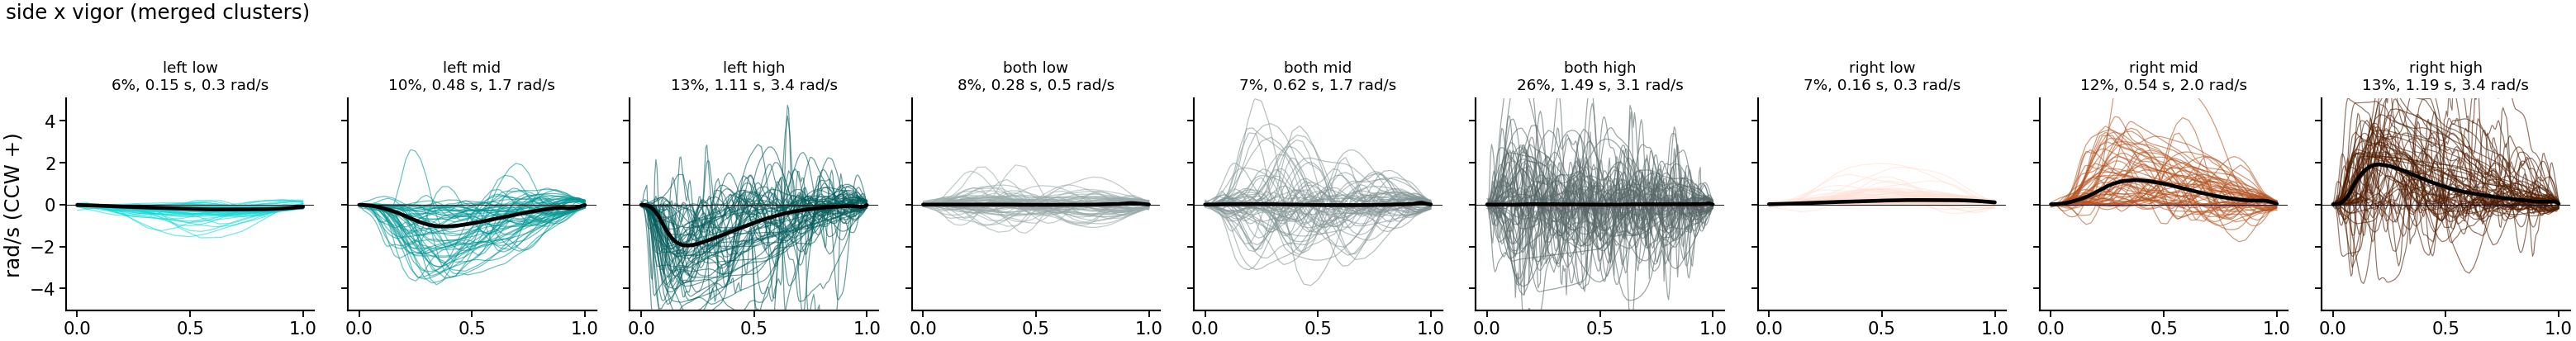

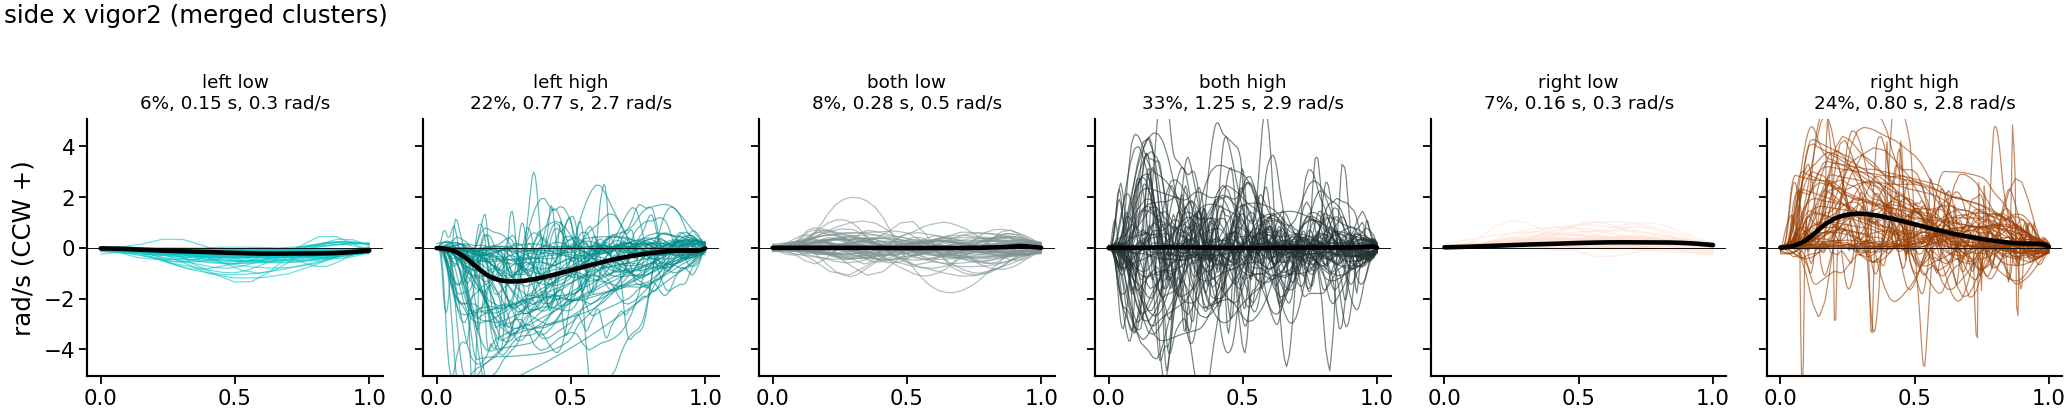

In [3]:
# what the side x vigor merges look like (members thin, median thick)
rng = np.random.default_rng(0)
def panel(col, names, title):
    side = np.array([{'left': -1, 'both': 0, 'right': 1}[n.split()[0]] for n in names], float)
    cols = ps.state_palette([np.log(IA.peak[IA[col] == n].median()) for n in names], gap=-wmc.CHROMA_SCALE * side, hues=wmc.WHEEL_HUES)
    fig, axs = plt.subplots(1, len(names), figsize=(1.6 * len(names), 2.0), sharey=True)
    for ax, n, c in zip(axs, names, cols):
        sel = np.flatnonzero(IA[col].values == n)
        ax.plot(x, SA[rng.choice(sel, min(60, len(sel)), replace=False)].T, c=c, lw=.4, alpha=.6)
        ax.plot(x, np.median(SA[sel], 0), c='k', lw=1.5); ax.axhline(0, c='k', lw=.3); ax.set_ylim(-YL, YL)
        q = IA.loc[sel]
        ax.set_title(f'{n}\n{len(sel) / len(IA):.0%}, {q.duration.median():.2f} s, {q.peak.median():.1f} rad/s', fontsize=6)
    axs[0].set_ylabel('rad/s (CCW +)'); fig.suptitle(title, fontsize=8, x=.01, ha='left'); plt.tight_layout(); plt.show()
panel('g9', ORDER9, 'side x vigor (merged clusters)')
panel('g6', [f'{s} {v}' for s in wmc.SIDES for v in ('low', 'high')], 'side x vigor2 (merged clusters)')

## B · The paper's 8 states: one `small` state vs small CW / small CCW

The 8-state set puts every low-vigor cluster (median peak < 1 rad/s) into one `small` state: clusters 0, 1 (CW), 7, 8
(balanced), 13, 14 (CCW). Option **B** gives the second-smallest one-sided clusters (1, 14; ~0.5 rad/s, fully one-sided)
their own `CW small` / `CCW small` (10 states; balanced 8 stays in `small`). Colours as `wmc.colours`.

In [4]:
def nice(name):
    return ' '.join(DIRECTION.get(w, w) for w in name.split())

# option A: the paper's grouping; option B: the second-smallest one-sided clusters get their own directed state
GROUP = {'A': [nice(g) for g in wmc.group_of(WM, 'small_side_vigor')]}
_b = list(GROUP['A'])
for c in range(WK):
    if WD.vigor[c] == 'low' and WD.side[c] != 'both':
        lows = WD.index[(WD.vigor == 'low') & (WD.side == WD.side[c])]
        if c != lows[np.argmin(WD.peak_rad_s[lows])]:          # not the smallest of its direction
            _b[c] = f'{DIRECTION[WD.side[c]]} small'
GROUP['B'] = _b

def state_colours(groups):
    """wmc.colours' rule for any grouping of the 20 clusters -> {state name: colour}."""
    g = np.array(groups); names = list(dict.fromkeys(groups)); w = WD.fraction.values
    vig = [np.log(np.average(WD.peak_rad_s.values[g == n], weights=w[g == n])) for n in names]
    side = [np.average(WD.side_index.values[g == n], weights=w[g == n]) for n in names]
    return dict(zip(names, ps.state_palette(vig, gap=-wmc.CHROMA_SCALE * np.array(side), hues=wmc.WHEEL_HUES)))
COLS_AB = {o: state_colours(GROUP[o]) for o in GROUP}
# same colours as the figure for option A
assert list(COLS_AB['A'].values()) == wmc.colours(WM, 'small_side_vigor')[1:]
pd.DataFrame({'peak': WD.peak_rad_s.round(2), 'A': GROUP['A'], 'B': GROUP['B']})

,peak,A,B
cluster,,,
0,0.24,small,small
1,0.51,small,CW small
2,1.21,CW mid,CW mid
3,2.29,CW mid,CW mid
4,2.95,CW high,CW high
5,3.09,CW high,CW high
6,4.25,CW high,CW high
7,0.35,small,small
8,0.65,small,small


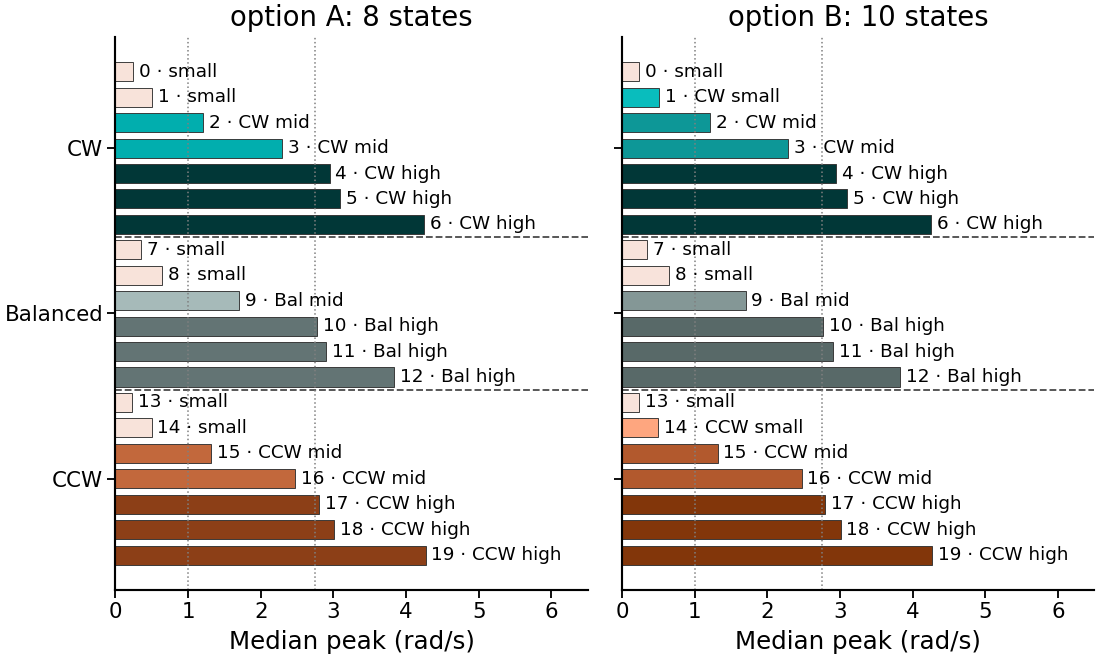

In [5]:
# the mapping, as in figure 1 g: one bar per cluster in its state's colour, per option
fig, axes = plt.subplots(1, 2, figsize=(5.2, 3.2), sharey=True)
y = -np.arange(WK)
for ax, o in zip(axes, GROUP):
    ax.barh(y, WD.peak_rad_s, color=[COLS_AB[o][g] for g in GROUP[o]], edgecolor='0.2', lw=0.3, height=0.75)
    for c in range(WK):
        ax.text(WD.peak_rad_s[c] + 0.08, -c, f'{c} · {GROUP[o][c]}', va='center', fontsize=6)
    for b in (6.5, 12.5):
        ax.axhline(-b, color='0.3', lw=0.6, ls='--')
    for v in wmc.VIGOR_CUTS:
        ax.axvline(v, color='0.5', lw=0.5, ls=':')
    ax.set(title=f'option {o}: {len(COLS_AB[o]) + 1} states', xlabel='Median peak (rad/s)', xlim=(0, 6.5))
axes[0].set_yticks([-3, -9.5, -16]); axes[0].set_yticklabels(['CW', 'Balanced', 'CCW'])
plt.tight_layout(); plt.show()

In [6]:
# example sessions: 20 mice, one session each; per session the 12 s window with the most distinct clusters,
# among windows that contain at least one of the clusters A and B disagree about
N_EX, WIN = 20, 12.0
DIFF = [c for c in range(WK) if GROUP['A'][c] != GROUP['B'][c]]
coh = wmc.fit_cohort()
rng = np.random.default_rng(1)
picks = coh.groupby('mouse').sample(1, random_state=1).sample(N_EX, random_state=1)

def snippet(mouse, eid):
    t, v, iv, tr = wmc.load_session('proficient', mouse, eid)
    S, info = wmc.shapes(t, v, iv)
    info['cluster'] = wmc.predict(WM, S, info.duration)
    best, t0 = -1, info.onset.min()
    for s in np.arange(info.onset.min(), info.offset.max() - WIN, WIN / 4):
        q = info[(info.onset >= s) & (info.offset <= s + WIN)]
        if not q.cluster.isin(DIFF).any():
            continue
        score = q.cluster.nunique() + 0.5 * q.cluster.isin(DIFF).sum()
        if score > best:
            best, t0 = score, s
    return dict(mouse=mouse, eid=eid, t=t, v=v, tr=tr, t0=t0,
                q=info[(info.onset >= t0 - 1) & (info.offset <= t0 + WIN + 1)])
SN = [snippet(m, e) for m, e in zip(picks.mouse, picks.eid)]
print(f'{len(SN)} snippets; clusters where A and B differ: {DIFF}')

20 snippets; clusters where A and B differ: [1, 14]


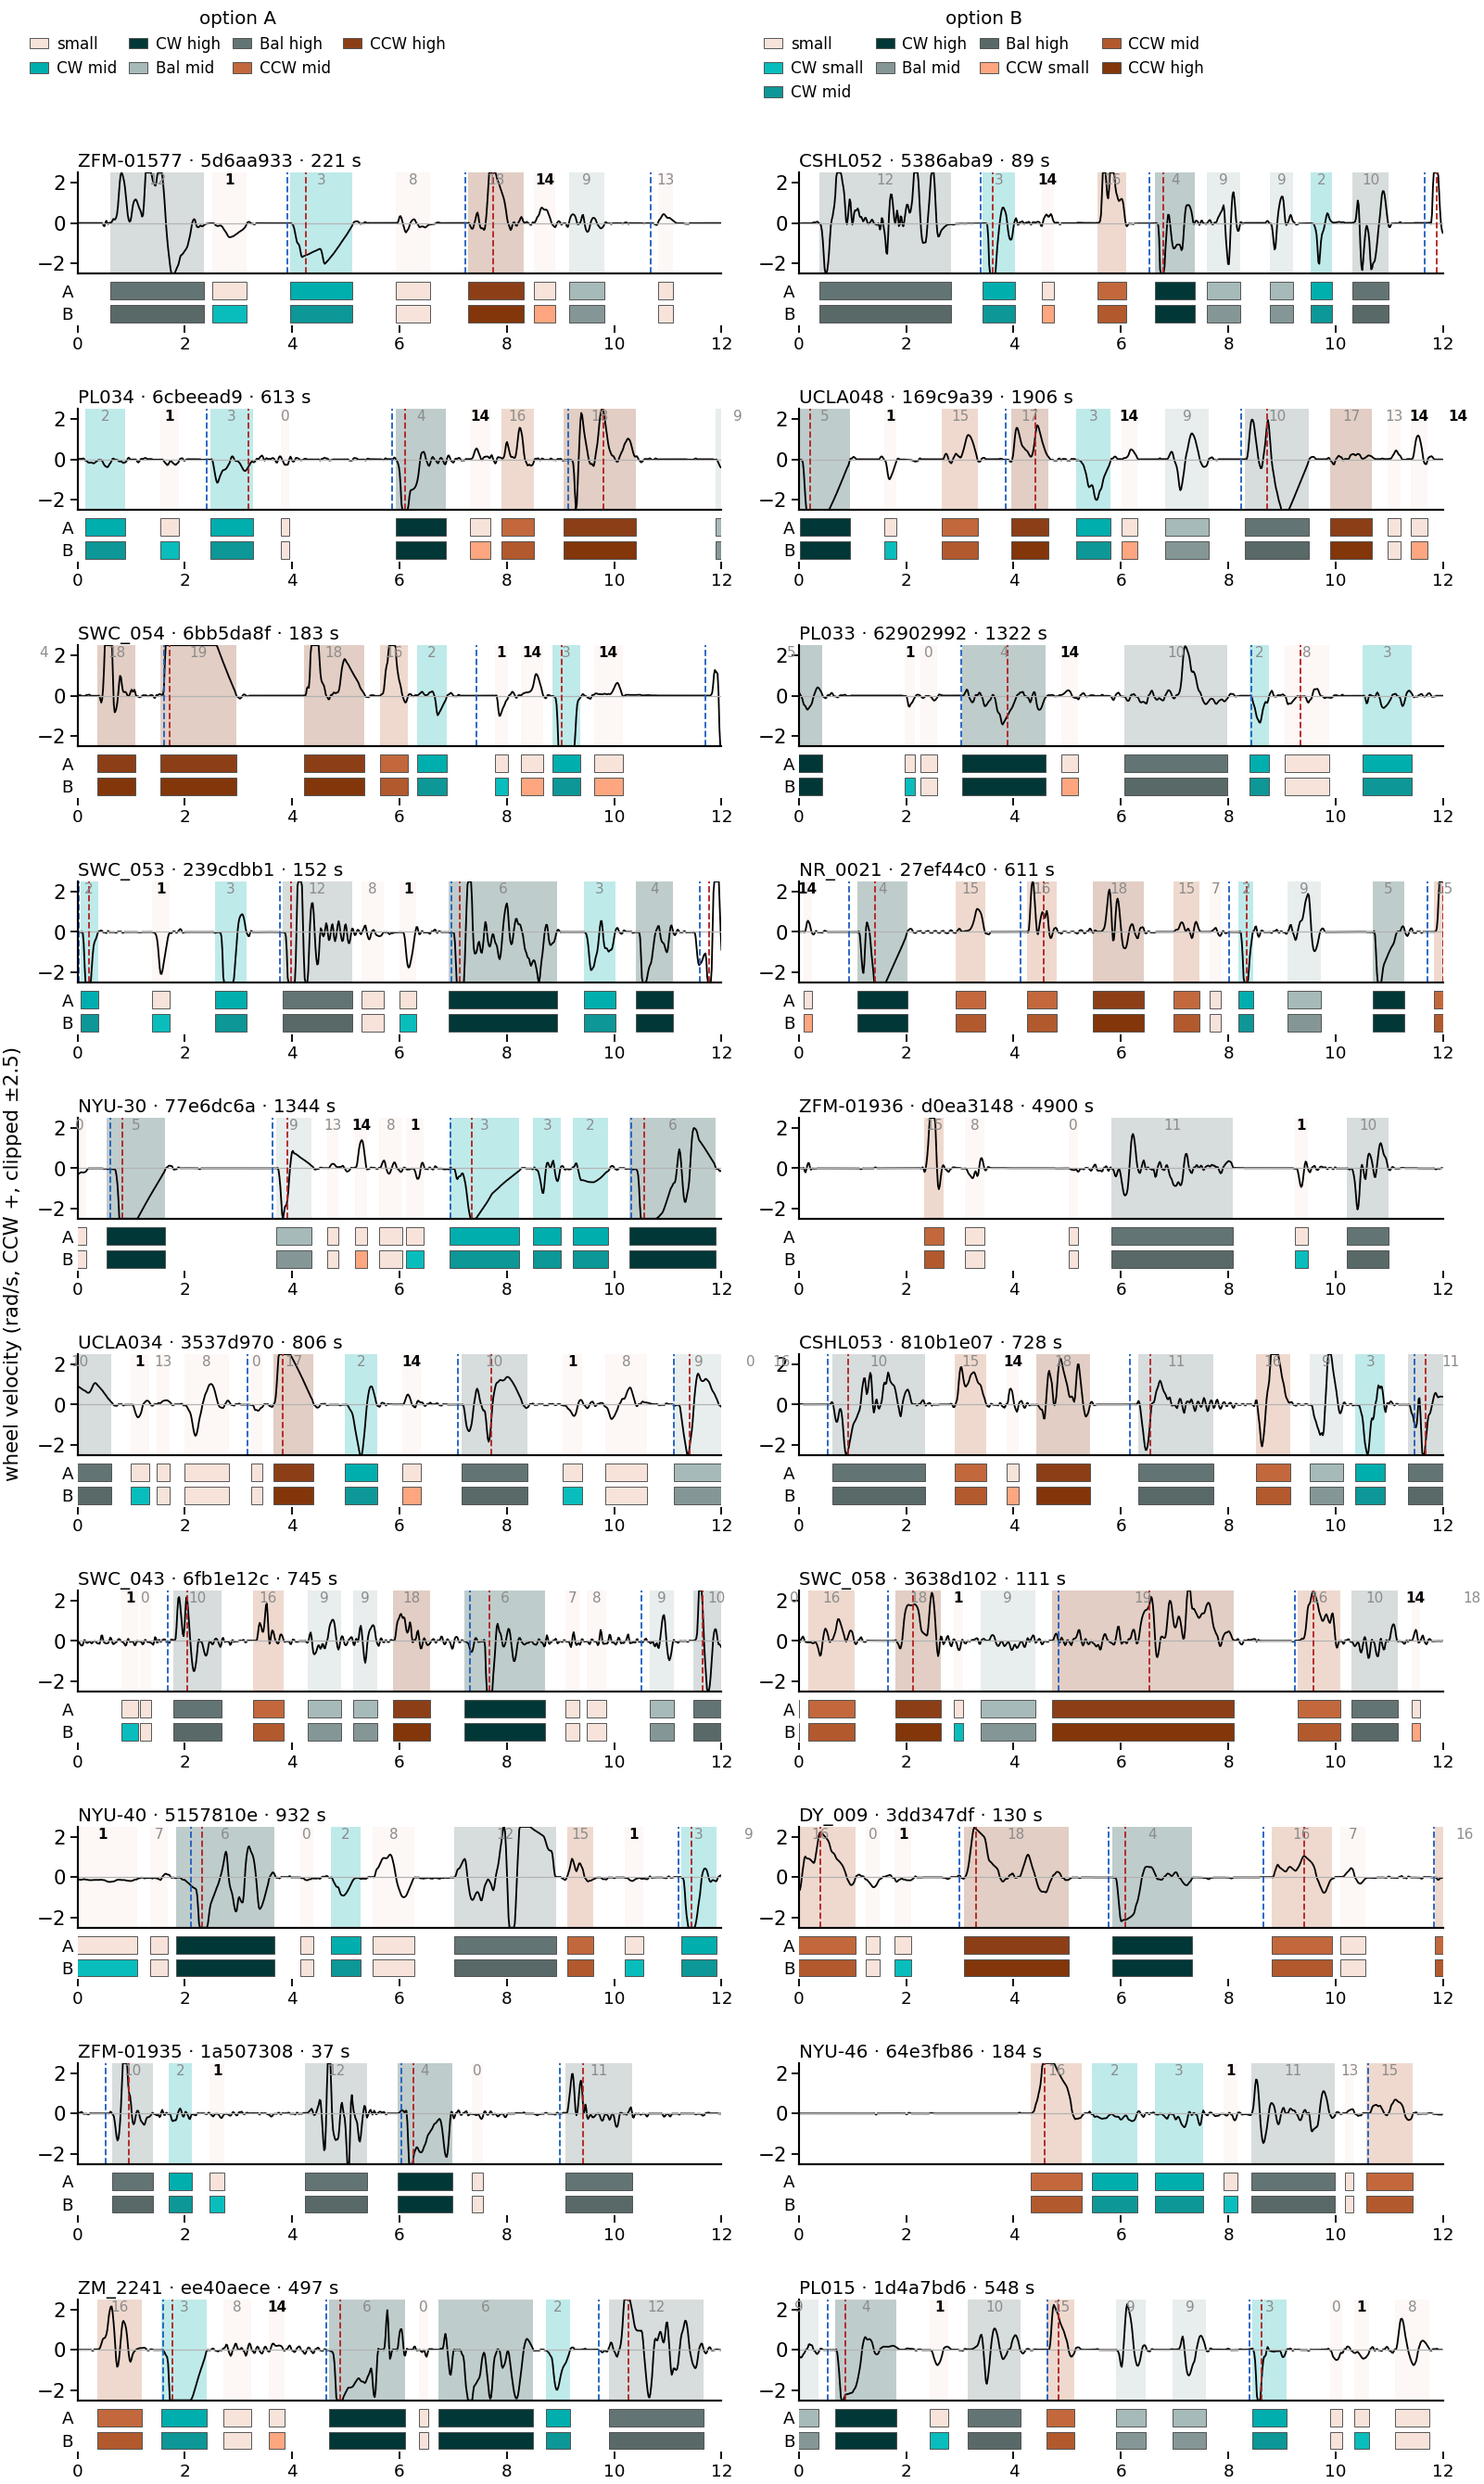

In [7]:
def draw_snippet(axv, axs, sn, lim=2.5):
    t, v, t0, q, tr = sn['t'], sn['v'], sn['t0'], sn['q'], sn['tr']
    sel = (t >= t0) & (t <= t0 + WIN)
    for _, r in q.iterrows():
        x0, x1 = r.onset - wmc.PAD_S - t0, r.offset + wmc.PAD_S - t0
        axv.axvspan(x0, x1, color=COLS_AB['A'][GROUP['A'][int(r.cluster)]], alpha=0.25, lw=0)
        axv.text((x0 + x1) / 2, lim * 0.98, str(int(r.cluster)), ha='center', va='top', fontsize=5,
                 color='k' if r.cluster in DIFF else '0.55', fontweight='bold' if r.cluster in DIFF else 'normal')
        for k, o in enumerate(GROUP):
            axs.axvspan(x0, x1, ymin=1 - (k + 1) / 2 + 0.06, ymax=1 - k / 2 - 0.06,
                        color=COLS_AB[o][GROUP[o][int(r.cluster)]], lw=0.3, ec='0.3')
    axv.plot(t[sel] - t0, np.clip(v[sel], -lim, lim), color='k', lw=0.6)
    axv.axhline(0, color='0.7', lw=0.4)
    for ev, c in (('stimOn_times', '#1f5fbf'), ('feedback_times', '#b22222')):
        for x in tr[ev].values - t0:
            if 0 <= x <= WIN:
                axv.axvline(x, color=c, lw=0.6, ls='--')
    axv.set(xlim=(0, WIN), ylim=(-lim, lim), xticks=[]); axv.set_yticks([-2, 0, 2])
    axv.set_title(f"{sn['mouse']} · {sn['eid'][:8]} · {t0:.0f} s", fontsize=6.5, pad=2, loc='left')
    axs.set(xlim=(0, WIN), ylim=(0, 1), yticks=[0.75, 0.25], yticklabels=list(GROUP))
    axs.tick_params(axis='y', length=0, labelsize=6); axs.tick_params(axis='x', labelsize=6)
    for s_ in axs.spines.values(): s_.set_visible(False)

def legend_handles(o):
    return [Patch(fc=c, ec='0.3', lw=0.3, label=n) for n, c in COLS_AB[o].items()]

ncol = 2
nrow = int(np.ceil(len(SN) / ncol))
fig = plt.figure(figsize=(7.2, 1.15 * nrow + 0.9))
gs = fig.add_gridspec(nrow, ncol, hspace=0.55, wspace=0.12, top=1 - 0.85 / (1.15 * nrow + 0.9), bottom=0.03, left=0.06, right=0.99)
for i, sn in enumerate(SN):
    g = gs[i // ncol, i % ncol].subgridspec(2, 1, height_ratios=[2.2, 1], hspace=0.08)
    draw_snippet(fig.add_subplot(g[0]), fig.add_subplot(g[1]), sn)
for k, o in enumerate(GROUP):
    fig.legend(handles=legend_handles(o), loc='upper left', bbox_to_anchor=(0.02 + 0.5 * k, 1.0), ncol=4,
               fontsize=5.5, frameon=False, title=f'option {o}', title_fontsize=6.5, handlelength=1.2, columnspacing=0.8)
fig.text(0.01, 0.5, 'wheel velocity (rad/s, CCW +, clipped ±2.5)', rotation=90, va='center', fontsize=7)
plt.show()

In [8]:
# where (epoch) the small states occur
for col, names in [('s8', np.array(_names8[1:])), ('s8_mid', np.array(order8))]:
    display(pd.crosstab(names[IA[col]], IA.epoch, normalize='index').reindex(columns=EPOCHS).round(2)
            .assign(n=pd.Series(names[IA[col]]).value_counts()).rename_axis(col))
low = IA[IA.s8 == _names8[1:].index('small')]
display(pd.crosstab(np.array(GROUP['B'])[low.c20], low.epoch, normalize='index').reindex(columns=EPOCHS).round(2)
        .rename_axis('option B, within paper small'))

epoch,pre-stim,response,post-feedback,n
s8,,,,
both high,0.22,0.59,0.19,101665
both mid,0.26,0.33,0.41,28378
left high,0.22,0.60,0.18,50106
left mid,0.25,0.34,0.40,37323
right high,0.21,0.58,0.21,49366
right mid,0.24,0.37,0.40,46201
small,0.18,0.17,0.65,78612


epoch,pre-stim,response,post-feedback,n
s8_mid,,,,
both high,0.22,0.59,0.19,101665
both mid,0.26,0.33,0.41,28378
left high,0.22,0.60,0.18,50106
left mid,0.23,0.30,0.47,49226
right high,0.21,0.58,0.21,49366
right mid,0.22,0.32,0.46,60246
small,0.18,0.18,0.65,52664


epoch,pre-stim,response,post-feedback
"option B, within paper small",,,
CCW small,0.17,0.17,0.66
CW small,0.17,0.17,0.66
small,0.18,0.18,0.65


## C · Split first (whole movement), then K clusters per direction, no merging
Same split and features as the paper model (shared PCA 95 % + log duration, same fit sample), GMMs with 2, 3 or 4
clusters per group (`wmc.fit` with its `KG` swapped), used as they are.

In [9]:
MODELS = {}
KG0 = wmc.KG
try:
    for k in (2, 3, 4):
        wmc.KG = (k, k, k)
        MODELS[k] = wmc.fit(S, info)
finally:
    wmc.KG = KG0
assert all(m['SIGN_RIGHT'] == 1 for m in MODELS.values())

NAMES = {k: name_clusters(m) for k, m in MODELS.items()}
COLS = {k: wmc.colours(m)[1:] for k, m in MODELS.items()}
for k, m in MODELS.items():
    IA[f'k{k}'] = wmc.predict(m, SA, IA.duration)
    CANDIDATES[f'whole-movement split, {k} per direction'] = f'k{k}'
for k, m in MODELS.items():
    d = m['desc'].assign(name=NAMES[k])
    display(d[['name', 'fraction', 'side_index', 'peak_rad_s', 'duration_s', 'reversals', 'response', 'post_feedback']].round(2))

,name,fraction,side_index,peak_rad_s,duration_s,reversals,response,post_feedback
cluster,,,,,,,,
0,CW 1,0.10,-1.00,0.59,0.25,0.0,0.23,0.58
1,CW 2,0.17,-0.79,3.07,0.93,2.0,0.57,0.21
2,Bal 1,0.11,-0.00,0.65,0.37,2.0,0.25,0.56
3,Bal 2,0.32,-0.01,3.04,1.41,5.0,0.60,0.19
4,CCW 1,0.10,1.00,0.47,0.22,0.0,0.21,0.61
5,CCW 2,0.20,0.84,2.90,0.91,2.0,0.55,0.26


,name,fraction,side_index,peak_rad_s,duration_s,reversals,response,post_feedback
cluster,,,,,,,,
0,CW 1,0.06,-1.00,0.34,0.15,0.0,0.16,0.66
1,CW 2,0.11,-0.91,1.92,0.51,1.0,0.43,0.36
2,CW 3,0.11,-0.74,3.47,1.19,2.0,0.60,0.18
3,Bal 1,0.07,-0.00,0.44,0.25,1.0,0.21,0.63
4,Bal 2,0.13,-0.02,1.89,0.70,2.0,0.41,0.35
5,Bal 3,0.24,-0.00,3.27,1.68,6.0,0.65,0.16
6,CCW 1,0.06,1.00,0.31,0.15,0.0,0.16,0.66
7,CCW 2,0.11,0.93,1.77,0.51,1.0,0.43,0.40
8,CCW 3,0.12,0.79,3.32,1.19,2.0,0.57,0.23


,name,fraction,side_index,peak_rad_s,duration_s,reversals,response,post_feedback
cluster,,,,,,,,
0,CW 1,0.04,-1.00,0.29,0.13,0.0,0.15,0.68
1,CW 2,0.06,-0.94,1.03,0.35,1.0,0.28,0.52
2,CW 3,0.09,-0.87,2.59,0.69,1.0,0.54,0.24
3,CW 4,0.08,-0.71,3.72,1.40,3.0,0.61,0.18
4,Bal 1,0.07,-0.00,0.44,0.24,1.0,0.21,0.63
5,Bal 2,0.12,-0.02,1.85,0.67,2.0,0.40,0.35
6,Bal 3,0.12,-0.01,2.86,1.87,7.0,0.68,0.15
7,Bal 4,0.12,0.00,3.61,1.44,5.0,0.61,0.18
8,CCW 1,0.05,1.00,0.27,0.13,0.0,0.16,0.66


In [10]:
# is the split decided by the groups? side of every refit cluster = its group (the median balance agrees)
for k, m in MODELS.items():
    inv = {v: r for r, v in m['REL'].items()}
    grp = [int(np.searchsorted(m['OFF'], inv[c], side='right') - 1) for c in range(m['K'])]
    print(k, 'per group:', list(m['desc'].side) == [wmc.SIDES[g] for g in grp])

2 per group: True
3 per group: True
4 per group: True


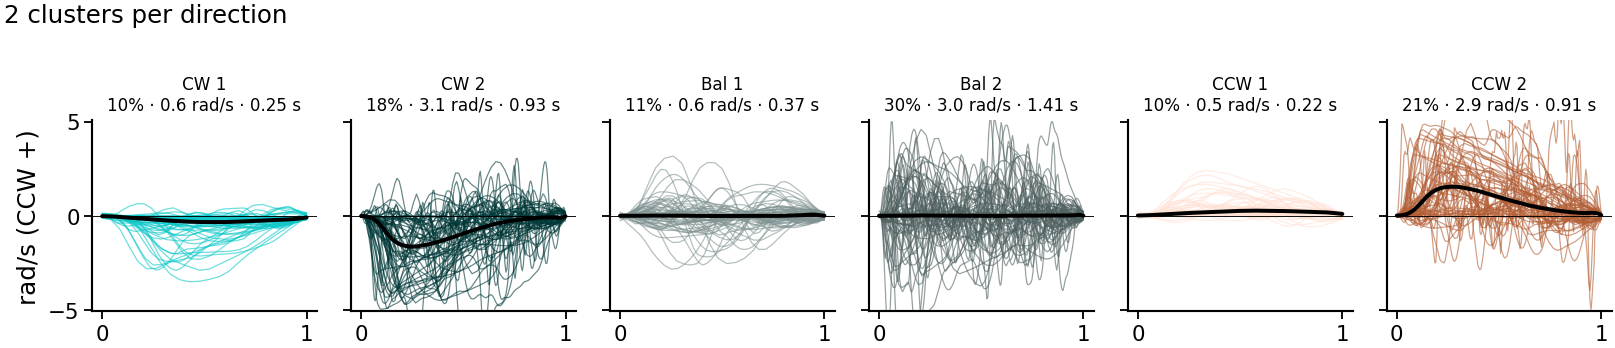

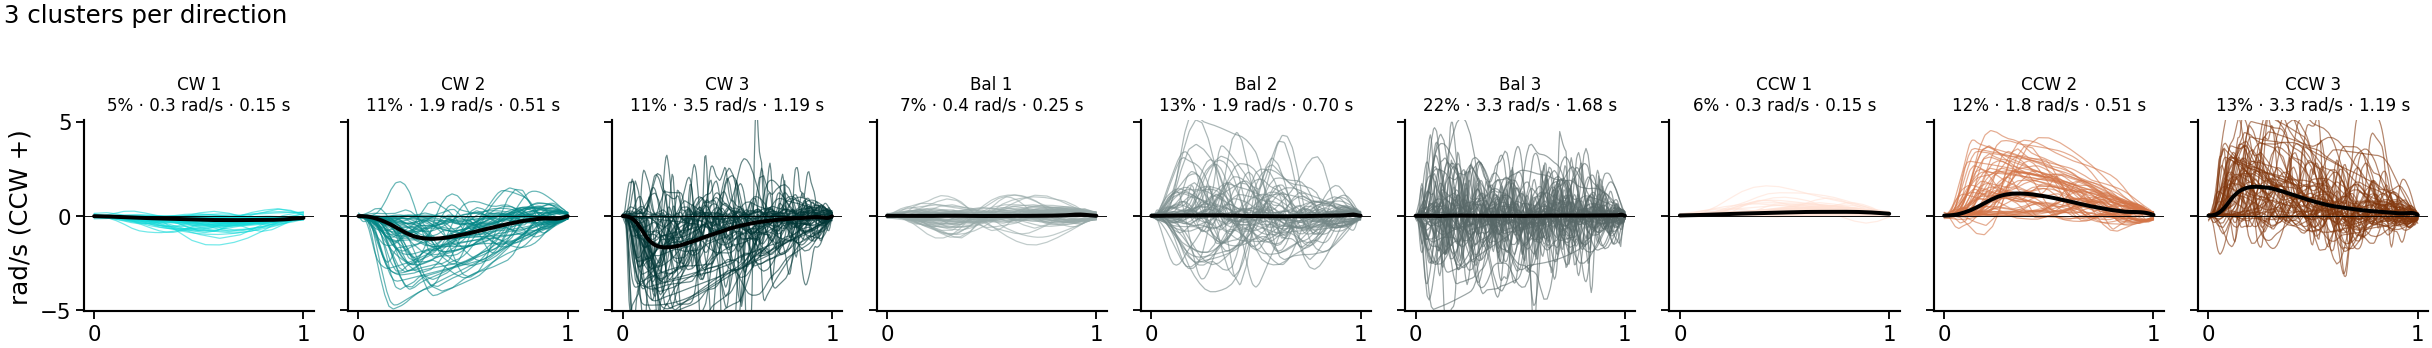

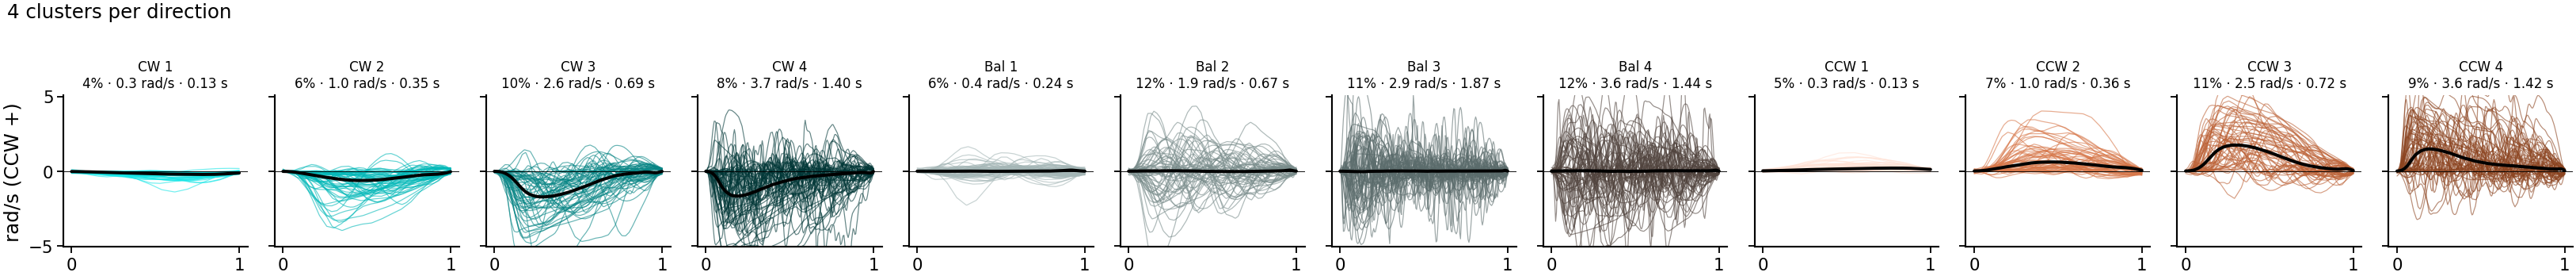

In [11]:
# members (60 random) + median of every cluster, absolute velocity, one row per K
rng = np.random.default_rng(0)
for k, m in MODELS.items():
    lab = IA[f'k{k}'].values
    fig, axs = plt.subplots(1, m['K'], figsize=(1.25 * m['K'], 1.7), sharey=True)
    for c, ax in enumerate(axs):
        a = SA[lab == c]
        ax.plot(x, a[rng.choice(len(a), min(60, len(a)), replace=False)].T, c=COLS[k][c], lw=.4, alpha=.6)
        ax.plot(x, np.median(a, 0), c='k', lw=1.3); ax.axhline(0, c='k', lw=.3); ax.set(ylim=(-YL, YL), xticks=[0, 1])
        ax.set_title(f'{NAMES[k][c]}\n{(lab == c).mean():.0%} · {m["desc"].peak_rad_s[c]:.1f} rad/s · '
                     f'{m["desc"].duration_s[c]:.2f} s', fontsize=5.5)
    axs[0].set_ylabel('rad/s (CCW +)')
    fig.suptitle(f'{k} clusters per direction', fontsize=8, x=0.01, ha='left'); plt.tight_layout(); plt.show()

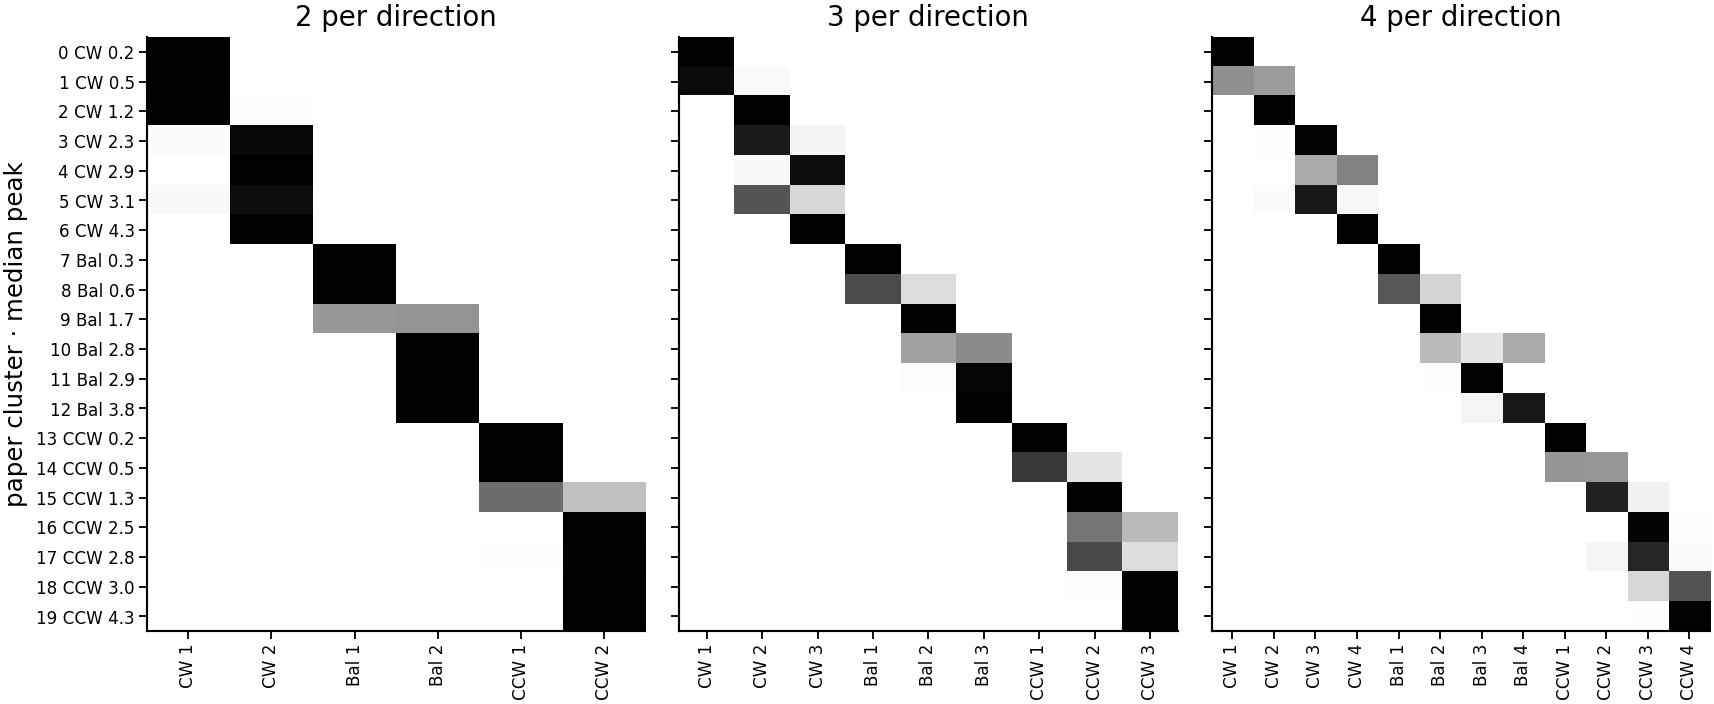

In [12]:
# how the refits relate to the paper's 20 clusters (row-normalised: where each paper cluster goes)
fig, axs = plt.subplots(1, 3, figsize=(8, 3.4), sharey=True)
pn = [f'{c} {DIRECTION[PAPER["desc"].side[c]]} {PAPER["desc"].peak_rad_s[c]:.1f}' for c in range(PAPER['K'])]
for ax, (k, m) in zip(axs, MODELS.items()):
    ct = pd.crosstab(IA.c20, IA[f'k{k}'], normalize='index')
    ax.imshow(ct.values, cmap='Greys', vmin=0, vmax=1, aspect='auto')
    ax.set(xticks=range(m['K']), title=f'{k} per direction')
    ax.set_xticklabels(NAMES[k], rotation=90, fontsize=5.5)
axs[0].set_yticks(range(PAPER['K'])); axs[0].set_yticklabels(pn, fontsize=5.5); axs[0].set_ylabel('paper cluster · median peak')
plt.tight_layout(); plt.show()

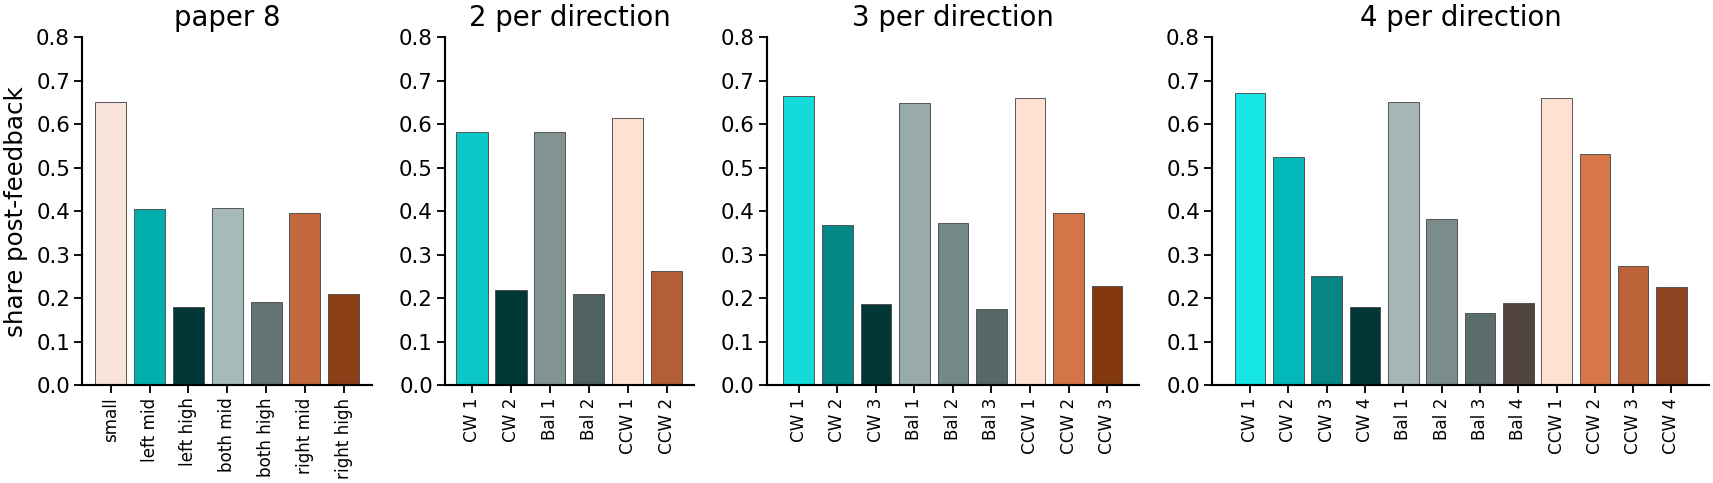

In [13]:
# when they happen: epoch share of every cluster
fig, axs = plt.subplots(1, 4, figsize=(8, 2.4), gridspec_kw=dict(width_ratios=[7, 6, 9, 12]))
for ax, (lbl, col, names, cols) in zip(axs, [('paper 8', 's8', _names8[1:], COL8)] +
                                       [(f'{k} per direction', f'k{k}', NAMES[k], COLS[k]) for k in MODELS]):
    ct = pd.crosstab(IA[col], IA.epoch, normalize='index').reindex(columns=EPOCHS)
    ax.bar(range(len(ct)), ct['post-feedback'], color=cols, ec='0.3', lw=0.3)
    ax.set(ylim=(0, 0.8), title=lbl, xticks=range(len(ct)))
    ax.set_xticklabels(names, rotation=90, fontsize=5.5)
axs[0].set_ylabel('share post-feedback')
plt.tight_layout(); plt.show()

### How many clusters per direction? BIC per group
For each split group (CW / balanced / CCW, whole-movement split as in the paper), a GMM with K = 1 … 12 on the same
features and fit sample (full covariance, `n_init` and seed as the paper model). Lower BIC = better; AIC for reference.
Caveat: with ~40k movements per group BIC's penalty is small next to the likelihood, and movement shapes are not
Gaussian blobs, so BIC may keep falling (more components to describe a continuum) rather than show a clear minimum.

movements per group in the fit sample: {'CW': np.int64(31137), 'Bal': np.int64(50297), 'CCW': np.int64(34622)}


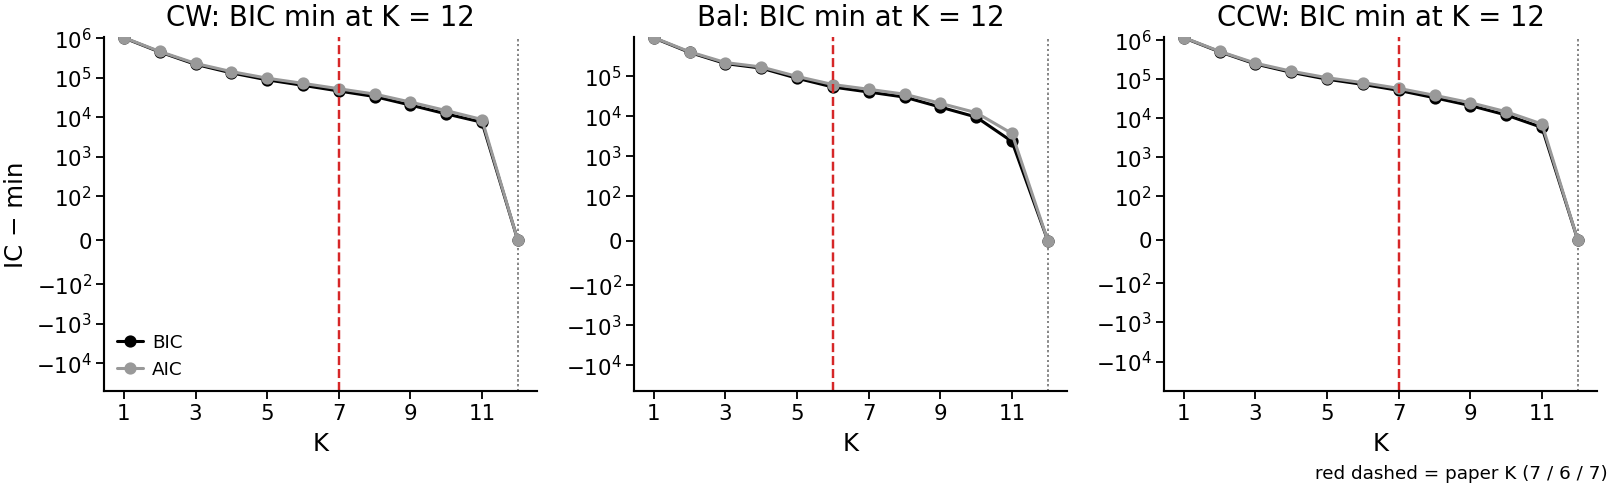

group,CW,Bal,CCW
"BIC drop K-1 -> K, rel. to 1 -> 2",,,
1,NaN,NaN,NaN
2,1.000,1.000,1.000
3,0.401,0.362,0.398
4,0.149,0.093,0.148
5,0.077,0.136,0.077
6,0.042,0.069,0.041
7,0.031,0.026,0.034
8,0.022,0.020,0.028
9,0.023,0.026,0.019


In [14]:
F_fit = wmc._features(PAPER, S, info.duration)
grp_fit = wmc.side_group(S, PAPER['SPLIT'])
KS_BIC = range(1, 13)
def _ic(g, k):
    gm = GaussianMixture(k, covariance_type='full', n_init=wmc.N_INIT, random_state=wmc.SEED).fit(F_fit[grp_fit == g])
    return g, k, gm.bic(F_fit[grp_fit == g]), gm.aic(F_fit[grp_fit == g])
BIC = pd.DataFrame(Parallel(n_jobs=12)(delayed(_ic)(g, k) for g in range(3) for k in KS_BIC), columns=['group', 'K', 'BIC', 'AIC'])
BIC['group'] = BIC.group.map({0: 'CW', 1: 'Bal', 2: 'CCW'})
print('movements per group in the fit sample:', dict(zip(['CW', 'Bal', 'CCW'], np.bincount(grp_fit))))
fig, axs = plt.subplots(1, 3, figsize=(7.5, 2.3))
for ax, (g, d) in zip(axs, BIC.groupby('group', sort=False)):
    for col, c in (('BIC', 'k'), ('AIC', '0.6')):
        ax.plot(d.K, d[col] - d[col].min(), 'o-', color=c, ms=3, lw=1, label=col)
        kmin = int(d.K.values[np.argmin(d[col].values)]); ax.axvline(kmin, color=c, lw=0.6, ls=':')
    ax.axvline(PAPER['KG'][['CW', 'Bal', 'CCW'].index(g)], color='tab:red', lw=0.8, ls='--')
    ax.set(title=f'{g}: BIC min at K = {int(d.K.values[np.argmin(d.BIC.values)])}', xlabel='K', xticks=list(KS_BIC)[::2])
    ax.set_yscale('symlog', linthresh=100)
axs[0].set_ylabel('IC − min'); axs[0].legend(fontsize=6, frameon=False)
fig.text(0.99, 0.01, 'red dashed = paper K (7 / 6 / 7)', ha='right', fontsize=6)
plt.tight_layout(); plt.show()
# gain per added cluster: how much BIC drops from K-1 to K, relative to the 1 -> 2 drop
BIC['drop_rel'] = BIC.groupby('group').BIC.transform(lambda b: -b.diff() / -(b.iloc[1] - b.iloc[0]))
display(BIC.pivot(index='K', columns='group', values='drop_rel')[['CW', 'Bal', 'CCW']].round(3).rename_axis('BIC drop K-1 -> K, rel. to 1 -> 2'))

In [15]:
# how similar are the refits to the paper's 8 states (and 20 clusters), movement by movement?
pd.DataFrame({f'whole-movement split, {k} per direction': {'ARI with paper 8': ari(IA.s8, IA[f'k{k}']),
                                                            'ARI with paper 20': ari(IA.c20, IA[f'k{k}']),
                                                            'NMI with paper 8': nmi(IA.s8, IA[f'k{k}'])} for k in MODELS}).T.round(3)

,ARI with paper 8,ARI with paper 20,NMI with paper 8
"whole-movement split, 2 per direction",0.638,0.370,0.724
"whole-movement split, 3 per direction",0.659,0.482,0.767
"whole-movement split, 4 per direction",0.474,0.579,0.709


## D · No split: sign-aligned shapes, direction post hoc from the first half

Problem seen above: IBL often merges the choice push and the back-and-forth that follows into one movement, so its
**whole-movement** travel balance is ~0 and it lands in `Bal L` -- the direction of the choice is lost.

Alternative, with **no split before clustering**:
1. **Direction** of a movement = sign of its net travel over the **first half** of the (time-normalised) movement.
   Compared below with the whole-movement balance on the choice movement of correct trials (it should report the stimulus side).
2. **Align**: flip every movement so its first half goes +. Mirror images become one shape, so a symmetric Gaussian no
   longer has to cover both signs (the reason the unsplit absolute fit made concentric, mixed-sign shells in `5` Part B).
3. **One GMM** on the aligned shapes (PCA 95 % + log duration, z-scored, same fit sample), K shapes.
4. **States = shape × direction** (2K). A push that comes back / oscillates is now a *shape* (with the direction of its
   initial push), not a 'balanced' class.

In [16]:
HALF = wmc.NT // 2
def first_half_sign(S):
    d = np.sign(S[:, :HALF].sum(1)); d[d == 0] = 1
    return d.astype(int)
def whole_balance(S):
    return wmc.balance(S)

# 1. which rule reports the choice? the first movement of the response epoch, correct trials (+ = CCW = right stimulus)
IA['dir_half'] = first_half_sign(SA)
ch = IA[(IA.epoch == 'response') & IA.correct & (IA.trial >= 0)].sort_values('onset').groupby(['eid', 'trial']).head(1)
want = np.where(ch.stim_side == 'right', 1, -1)
rows = {'whole movement, sign of balance': np.mean(np.sign(ch.balance) == want),
        'whole movement, |balance| > 0.5 (paper split; balanced = wrong)': np.mean(np.where(np.abs(ch.balance) > .5, np.sign(ch.balance), 0) == want),
        'first half, sign of net travel': np.mean(ch.dir_half == want)}
print(f'{len(ch):,} choice movements (first response-epoch movement, correct trials)')
display(pd.Series(rows, name='matches the reported side').round(3).to_frame())
# where the paper split calls the choice movement balanced, what does the first half say?
bal = ch[np.abs(ch.balance) <= .5]
print(f'{len(bal) / len(ch):.1%} of choice movements are balanced by the paper rule; '
      f'first-half direction matches the reported side for {np.mean(bal.dir_half == np.where(bal.stim_side == "right", 1, -1)):.1%} of them')

121,930 choice movements (first response-epoch movement, correct trials)


,matches the reported side
"whole movement, sign of balance",0.844
"whole movement, |balance| > 0.5 (paper split; balanced = wrong)",0.534
"first half, sign of net travel",0.900


44.2% of choice movements are balanced by the paper rule; first-half direction matches the reported side for 82.6% of them


In [17]:
# 2-3. align and fit one GMM, K shapes
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
d_fit = first_half_sign(S)
S_al = S * d_fit[:, None]
pca_al = PCA().fit(S_al)
n_pc_al = int(np.searchsorted(np.cumsum(pca_al.explained_variance_ratio_), wmc.VAR) + 1)
F0 = np.column_stack([pca_al.transform(S_al)[:, :n_pc_al], np.log10(info.duration)])
MU_al, SD_al = F0.mean(0), F0.std(0)
def feats_al(Sx, dur, d):
    return (np.column_stack([pca_al.transform(Sx * d[:, None])[:, :n_pc_al], np.log10(dur)]) - MU_al) / SD_al
SA_dir = IA.dir_half.values
FA = feats_al(SA, IA.duration.values, SA_dir)
ALIGNED = {}
for k in (3, 4):
    gm = GaussianMixture(k, covariance_type='full', n_init=wmc.N_INIT, random_state=wmc.SEED).fit((F0 - MU_al) / SD_al)
    raw = gm.predict(FA)
    peak = pd.Series(IA.peak.values).groupby(raw).median()
    order = {int(r): i for i, r in enumerate(peak.sort_values().index)}       # shape number by median peak
    ALIGNED[k] = np.array([order[r] for r in raw])
    IA[f'al{k}'] = ALIGNED[k]
    IA[f'al{k}x'] = ALIGNED[k] * 2 + (SA_dir > 0)                              # state = shape x direction
    CANDIDATES[f'no split, {k} aligned shapes x 2 dir'] = f'al{k}x'
print(f'aligned PCA: {n_pc_al} PCs (vs {MODELS[3]["n_pc"]} signed)')

aligned PCA: 17 PCs (vs 15 signed)


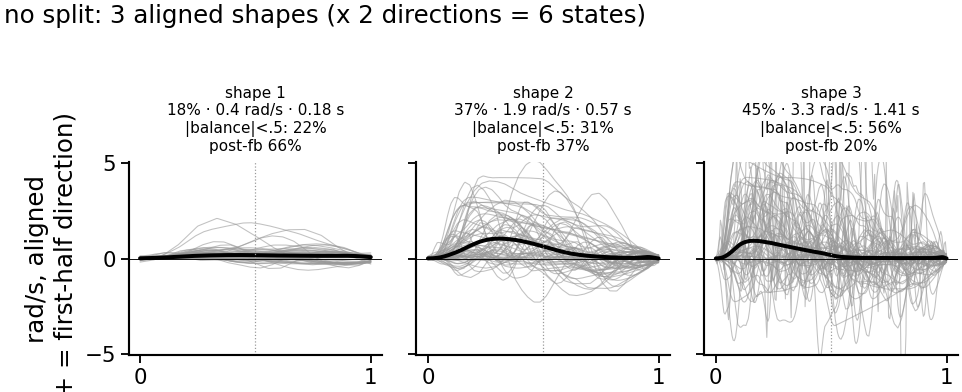

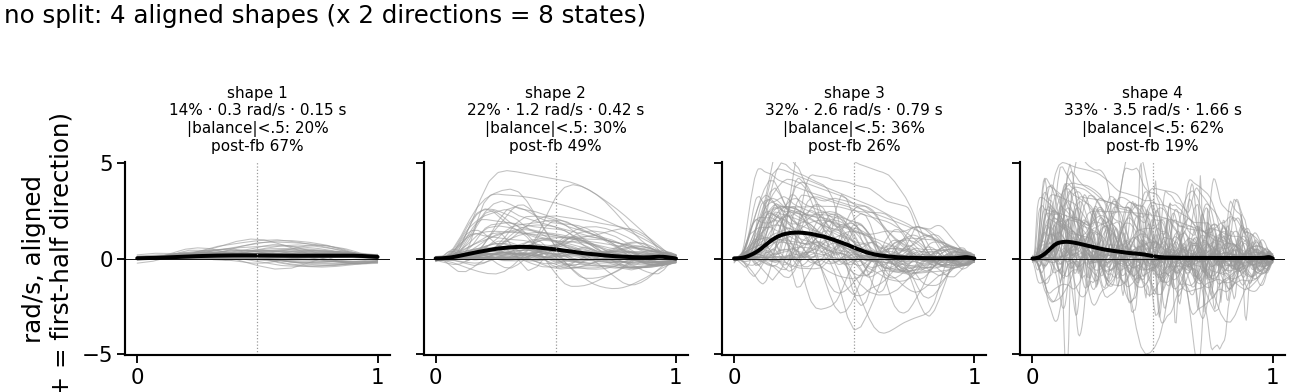

In [18]:
# shapes (aligned: + = the direction of the first half), members + median, per K
rng = np.random.default_rng(0)
SA_al = SA * SA_dir[:, None]
YLa = np.percentile(np.abs(SA_al), 99.5)
for k in ALIGNED:
    lab = ALIGNED[k]
    vig = [np.log(np.median(IA.peak.values[lab == c])) for c in range(k)]
    cols = ps.state_palette(vig, hues=wmc.WHEEL_HUES)
    fig, axs = plt.subplots(1, k, figsize=(1.5 * k, 1.9), sharey=True)
    for c, ax in enumerate(axs):
        m = lab == c; a = SA_al[m]
        ax.plot(x, a[rng.choice(len(a), min(60, len(a)), replace=False)].T, c='0.6', lw=.35, alpha=.6)
        ax.plot(x, np.median(a, 0), c='k', lw=1.3); ax.axhline(0, c='k', lw=.3); ax.axvline(0.5, c='0.6', lw=.4, ls=':')
        ax.set(ylim=(-YLa, YLa), xticks=[0, 1])
        ax.set_title(f'shape {c + 1}\n{m.mean():.0%} · {np.median(IA.peak[m]):.1f} rad/s · {np.median(IA.duration[m]):.2f} s\n'
                     f'|balance|<.5: {np.mean(np.abs(IA.balance[m]) <= .5):.0%}\npost-fb {np.mean(IA.epoch[m] == "post-feedback"):.0%}',
                     fontsize=5)
    axs[0].set_ylabel('rad/s, aligned\n(+ = first-half direction)')
    fig.suptitle(f'no split: {k} aligned shapes (x 2 directions = {2 * k} states)', fontsize=8, x=0.01, ha='left')
    plt.tight_layout(); plt.show()

In [19]:
# where the split-first states go: rows = 3-per-direction (split) cluster, columns = aligned shape x direction (K = 3, 4)
for k in (3, 4):
    ct = pd.crosstab(pd.Series(np.array(NAMES[3])[IA.k3], name='split 3x3'),
                     pd.Series([f'{"CCW" if d > 0 else "CW"} {s + 1}' for s, d in zip(IA[f'al{k}'], SA_dir)], name=f'aligned {k} x dir'),
                     normalize='index')
    display(ct.reindex(NAMES[3]).round(2).style.background_gradient(cmap='Greys', vmin=0, vmax=1, axis=None).format('{:.2f}'))

aligned 3 x dir,CCW 1,CCW 2,CCW 3,CW 1,CW 2,CW 3
split 3x3,,,,,,
CW 1,0.01,0.00,0.00,0.99,0.00,0.00
CW 2,0.00,0.02,0.00,0.09,0.88,0.00
CW 3,0.00,0.00,0.02,0.00,0.19,0.79
Bal 1,0.30,0.20,0.00,0.32,0.18,0.00
Bal 2,0.00,0.36,0.15,0.00,0.35,0.14
Bal 3,0.00,0.00,0.49,0.00,0.00,0.51
CCW 1,0.99,0.00,0.00,0.01,0.00,0.00
CCW 2,0.12,0.85,0.00,0.00,0.02,0.00
CCW 3,0.00,0.21,0.78,0.00,0.00,0.01


aligned 4 x dir,CCW 1,CCW 2,CCW 3,CCW 4,CW 1,CW 2,CW 3,CW 4
split 3x3,,,,,,,,
CW 1,0.01,0.00,0.00,0.00,0.94,0.05,0.00,0.00
CW 2,0.00,0.02,0.01,0.00,0.00,0.62,0.36,0.00
CW 3,0.00,0.00,0.01,0.01,0.00,0.00,0.48,0.50
Bal 1,0.21,0.29,0.00,0.00,0.22,0.28,0.00,0.00
Bal 2,0.00,0.11,0.39,0.01,0.00,0.11,0.38,0.01
Bal 3,0.00,0.00,0.04,0.46,0.00,0.00,0.04,0.47
CCW 1,0.98,0.01,0.00,0.00,0.01,0.00,0.00,0.00
CCW 2,0.01,0.62,0.34,0.00,0.00,0.02,0.00,0.00
CCW 3,0.00,0.00,0.49,0.50,0.00,0.00,0.01,0.01


## E · Split on the first half of the movement, then K clusters per direction

Same as the paper pipeline (`wheel_movement_clusters.fit`: shared PCA 95 % + log duration, one GMM per group, same fit
sample) except that the **travel balance used for the split is computed on the first half** of each (time-normalised)
movement: `|balance_first_half| > 0.5` → CW / CCW, else balanced. The choice push followed by a return or oscillation
now keeps the direction of the push. K = 2 … 5 clusters in every group, used as they are (no merging).

Implementation: `wmc.balance` is swapped for the first-half version while fitting **and** predicting (the split, the
cluster description's `side_index` and `side` all use it); restored afterwards. 

In [20]:
from contextlib import contextmanager
_whole_balance = wmc.balance
def half_balance(Sx):
    return _whole_balance(Sx[:, :HALF])
@contextmanager
def first_half_split():
    wmc.balance = half_balance
    try:
        yield
    finally:
        wmc.balance = _whole_balance

# how the groups change, and does the split report the choice? (choice movements `ch` from D)
IA['hbal'] = half_balance(SA)
grp = lambda b: np.where(b > .5, 'CCW', np.where(b < -.5, 'CW', 'Bal'))
display(pd.crosstab(pd.Series(grp(IA.balance.values), name='whole-movement split'),
                    pd.Series(grp(IA.hbal.values), name='first-half split'), margins=True, normalize='all').round(3))
want = np.where(ch.stim_side == 'right', 'CCW', 'CW')
hb = IA.loc[ch.index, 'hbal'].values
print(f'choice movements labelled with the reported side: whole-movement split {np.mean(grp(ch.balance.values) == want):.3f}, '
      f'first-half split {np.mean(grp(hb) == want):.3f}; called balanced: {np.mean(grp(ch.balance.values) == "Bal"):.1%} vs '
      f'{np.mean(grp(hb) == "Bal"):.1%}')

first-half split,Bal,CCW,CW,All
whole-movement split,,,,
Bal,0.204,0.104,0.101,0.409
CCW,0.019,0.291,0.002,0.312
CW,0.017,0.002,0.261,0.279
All,0.240,0.397,0.364,1.000


choice movements labelled with the reported side: whole-movement split 0.534, first-half split 0.685; called balanced: 44.2% vs 29.1%


In [21]:
HMODELS = {}
KG0 = wmc.KG
with first_half_split():
    try:
        for k in (2, 3, 4, 5):
            wmc.KG = (k, k, k)
            HMODELS[k] = wmc.fit(S, info)
            IA[f'h{k}'] = wmc.predict(HMODELS[k], SA, IA.duration)
            CANDIDATES[f'first-half split, {k} per direction'] = f'h{k}'
    finally:
        wmc.KG = KG0
assert wmc.balance is _whole_balance and wmc.KG == KG0
HNAMES = {k: name_clusters(m) for k, m in HMODELS.items()}
HCOLS = {k: wmc.colours(m)[1:] for k, m in HMODELS.items()}
for k in (3, 4):
    d = HMODELS[k]['desc'].assign(name=HNAMES[k])
    display(d[['name', 'fraction', 'side_index', 'peak_rad_s', 'duration_s', 'reversals', 'response', 'post_feedback']].round(2))

,name,fraction,side_index,peak_rad_s,duration_s,reversals,response,post_feedback
cluster,,,,,,,,
0,CW 1,0.08,-1.00,0.36,0.16,0.0,0.18,0.66
1,CW 2,0.13,-1.00,1.90,0.53,1.0,0.44,0.35
2,CW 3,0.14,-0.87,3.34,1.23,3.0,0.61,0.17
3,Bal 1,0.03,0.00,0.61,0.41,2.0,0.20,0.63
4,Bal 2,0.07,-0.00,2.32,0.90,3.0,0.46,0.31
5,Bal 3,0.15,-0.01,3.39,1.92,7.0,0.67,0.15
6,CCW 1,0.08,1.00,0.33,0.16,0.0,0.17,0.66
7,CCW 2,0.14,1.00,1.73,0.52,1.0,0.41,0.39
8,CCW 3,0.16,0.90,3.20,1.20,3.0,0.58,0.21


,name,fraction,side_index,peak_rad_s,duration_s,reversals,response,post_feedback
cluster,,,,,,,,
0,CW 1,0.06,-1.00,0.32,0.14,0.0,0.17,0.67
1,CW 2,0.07,-1.00,1.00,0.36,1.0,0.30,0.51
2,CW 3,0.12,-1.00,2.51,0.70,1.0,0.53,0.25
3,CW 4,0.11,-0.83,3.52,1.41,4.0,0.62,0.17
4,Bal 1,0.03,0.00,0.60,0.41,2.0,0.20,0.63
5,Bal 2,0.07,0.00,2.31,0.86,3.0,0.45,0.32
6,Bal 3,0.08,-0.02,2.94,2.03,8.0,0.69,0.14
7,Bal 4,0.08,-0.00,3.82,1.72,6.0,0.62,0.18
8,CCW 1,0.06,1.00,0.30,0.13,0.0,0.16,0.66


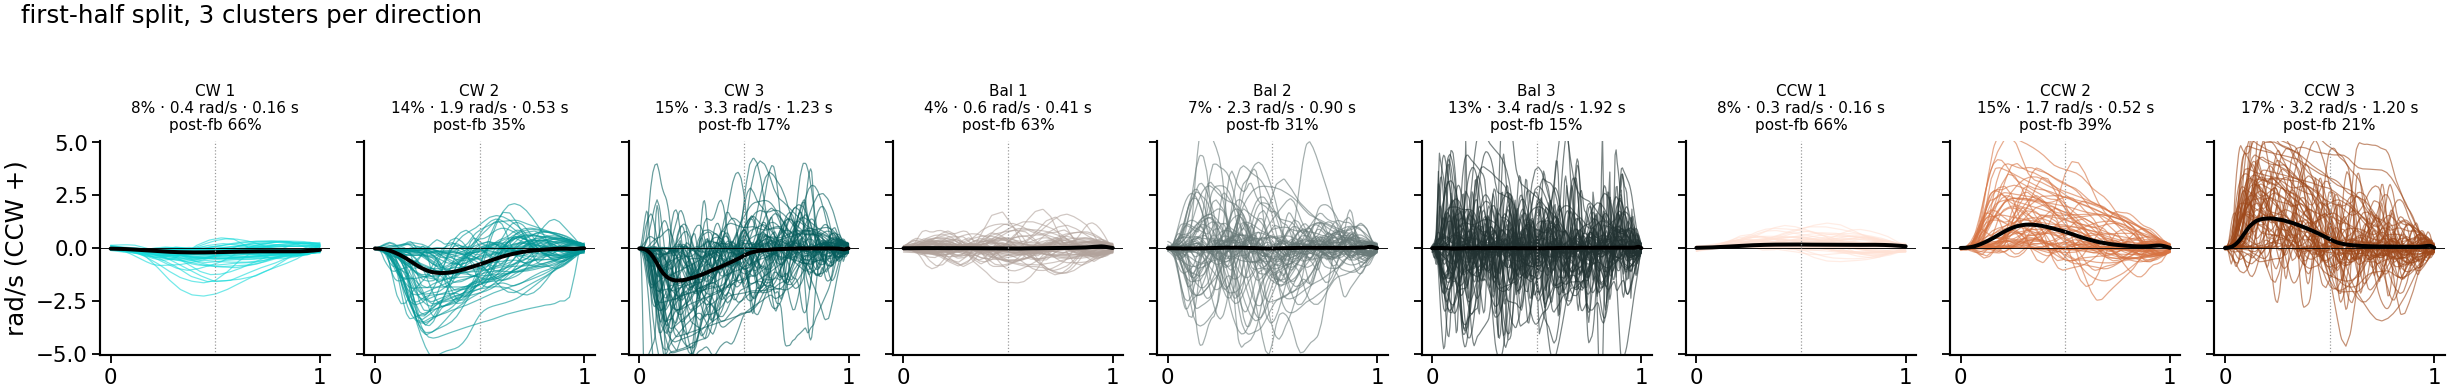

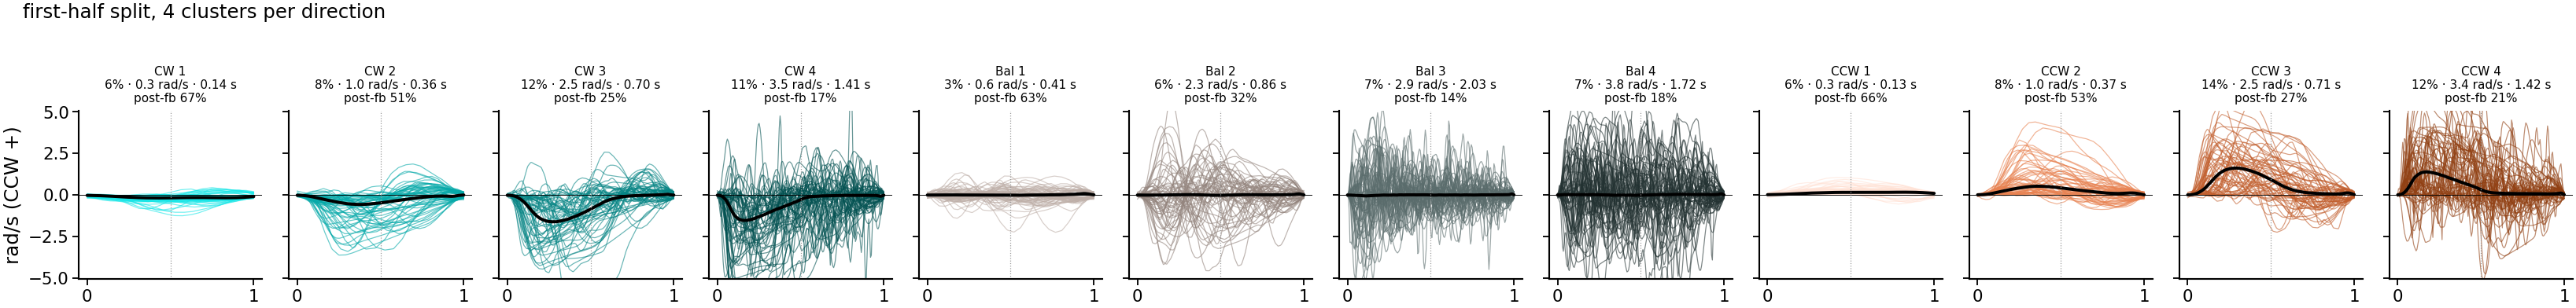

In [22]:
# members + median of every cluster, K = 3 and 4 (signed velocity, CCW +)
rng = np.random.default_rng(0)
for k in (3, 4):
    m_ = HMODELS[k]; lab = IA[f'h{k}'].values
    fig, axs = plt.subplots(1, m_['K'], figsize=(1.25 * m_['K'], 1.9), sharey=True)
    for c, ax in enumerate(axs):
        a = SA[lab == c]
        ax.plot(x, a[rng.choice(len(a), min(60, len(a)), replace=False)].T, c=HCOLS[k][c], lw=.4, alpha=.6)
        ax.plot(x, np.median(a, 0), c='k', lw=1.3); ax.axhline(0, c='k', lw=.3); ax.axvline(0.5, c='0.6', lw=.4, ls=':')
        ax.set(ylim=(-YL, YL), xticks=[0, 1])
        ax.set_title(f'{HNAMES[k][c]}\n{(lab == c).mean():.0%} · {m_["desc"].peak_rad_s[c]:.1f} rad/s · {m_["desc"].duration_s[c]:.2f} s\n'
                     f'post-fb {m_["desc"].post_feedback[c]:.0%}', fontsize=5)
    axs[0].set_ylabel('rad/s (CCW +)')
    fig.suptitle(f'first-half split, {k} clusters per direction', fontsize=8, x=0.01, ha='left'); plt.tight_layout(); plt.show()

## F · No split and no merge, then the same split post hoc
One GMM on all movements (the paper's features: shared PCA 95 % of the **signed** velocity + log duration, z-scored,
same fit sample), K = 6, 9, 20, used as they are. Each cluster's median whole-movement balance (CCW +) is shown, and
`mixed` = share of its one-sided movements (|balance| > 0.5) going against the cluster's majority sign.
Then each K = 6 cluster is divided **post hoc** by direction: × first-half sign (2K states) or × whole-movement
CW / balanced / CCW (3K).

In [23]:
from sklearn.mixture import GaussianMixture
F_fit = wmc._features(PAPER, S, info.duration)
F_all = wmc._features(PAPER, SA, IA.duration)
UMODELS, UDESC = {}, {}
for k in (6, 9, 20):
    gm = GaussianMixture(k, covariance_type='full', n_init=wmc.N_INIT, random_state=wmc.SEED).fit(F_fit)
    raw = gm.predict(F_all)
    d = (pd.DataFrame({'raw': raw, 'peak': IA.peak.values, 'dur': IA.duration.values, 'b': IA.balance.values,
                       'post_fb': (IA.epoch == 'post-feedback').values})
         .groupby('raw').agg(fraction=('raw', lambda x: len(x) / len(raw)), side_index=('b', 'median'),
                             peak_rad_s=('peak', 'median'), duration_s=('dur', 'median'), post_feedback=('post_fb', 'mean'),
                             mixed=('b', lambda b: np.mean(np.sign(b[np.abs(b) > .5]) != np.sign(np.median(b[np.abs(b) > .5])))
                                    if (np.abs(b) > .5).any() else np.nan)))
    d = d.sort_values('peak_rad_s')
    rel = {r: i for i, r in enumerate(d.index)}
    IA[f'u{k}'] = [rel[r] for r in raw]
    d = d.reset_index(drop=True); d.index.name = 'cluster'
    d['name'] = [f'U{c + 1} {"+" if s > .5 else "−" if s < -.5 else "±"}' for c, s in enumerate(d.side_index)]
    UMODELS[k], UDESC[k] = gm, d
    CANDIDATES[f'no split, no merge, K = {k}'] = f'u{k}'
UCOLS = {k: ps.state_palette(np.log(d.peak_rad_s.values), gap=-wmc.CHROMA_SCALE * d.side_index.values, hues=wmc.WHEEL_HUES)
         for k, d in UDESC.items()}
for k in (9, 20):
    display(UDESC[k][['name', 'fraction', 'side_index', 'mixed', 'peak_rad_s', 'duration_s', 'post_feedback']].round(2))
print('share of one-sided movements (|balance| > .5) in a cluster whose majority sign is the opposite:',
      {k: round(float(np.average(UDESC[k].mixed.fillna(0), weights=UDESC[k].fraction)), 3) for k in UDESC})

/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/sklearn/mixture/_base.py:275: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


,name,fraction,side_index,mixed,peak_rad_s,duration_s,post_feedback
cluster,,,,,,,
0,U1 +,0.06,0.96,0.44,0.23,0.10,0.66
1,U2 ±,0.09,0.05,0.47,0.44,0.20,0.67
2,U3 ±,0.13,0.01,0.49,0.93,0.37,0.54
3,U4 ±,0.15,0.01,0.49,1.99,0.56,0.38
4,U5 ±,0.06,0.43,0.46,2.79,0.78,0.19
5,U6 ±,0.18,0.03,0.47,2.85,0.86,0.26
6,U7 ±,0.09,0.04,0.45,2.98,1.28,0.14
7,U8 ±,0.10,0.01,0.45,3.02,2.07,0.16
8,U9 ±,0.13,0.01,0.49,4.16,1.72,0.23


,name,fraction,side_index,mixed,peak_rad_s,duration_s,post_feedback
cluster,,,,,,,
0,U1 +,0.04,1.00,0.44,0.21,0.09,0.65
1,U2 ±,0.07,0.06,0.46,0.37,0.16,0.68
2,U3 ±,0.08,0.03,0.48,0.62,0.28,0.63
3,U4 ±,0.05,-0.01,0.49,0.73,0.50,0.64
4,U5 ±,0.07,-0.00,0.50,1.83,0.41,0.38
5,U6 ±,0.03,0.03,0.46,2.01,1.31,0.32
6,U7 ±,0.08,0.02,0.47,2.31,0.60,0.35
7,U8 ±,0.05,0.08,0.46,2.38,0.70,0.29
8,U9 +,0.01,0.72,0.47,2.48,0.59,0.17


share of one-sided movements (|balance| > .5) in a cluster whose majority sign is the opposite: {6: 0.472, 9: 0.472, 20: 0.47}


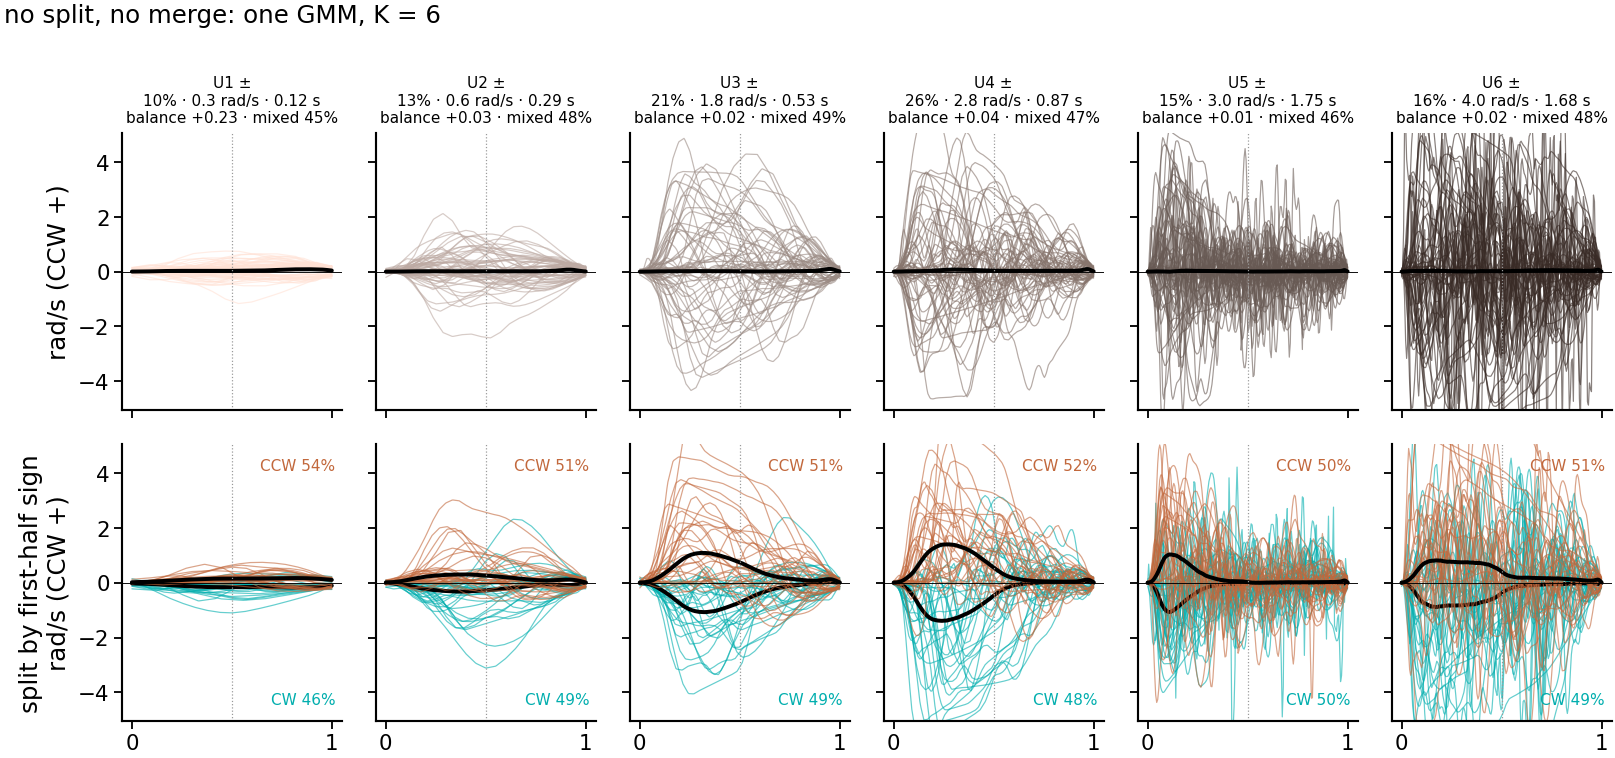

In [24]:
# members + median, no split / no merge, K = 6 (signed velocity, CCW +)
# top: every member in the cluster colour; bottom: the same cluster split post hoc by first-half sign (CW / CCW)
k = 6; lab = IA[f'u{k}'].values; rng = np.random.default_rng(0)
DIR_COL = {-1: COL8[_names8[1:].index('left mid')], 1: COL8[_names8[1:].index('right mid')]}   # teal CW, orange CCW
fig, axs = plt.subplots(2, k, figsize=(1.25 * k, 3.6), sharey=True, sharex=True)
for c in range(k):
    sel = np.flatnonzero(lab == c)
    ax = axs[0, c]
    ax.plot(x, SA[rng.choice(sel, min(60, len(sel)), replace=False)].T, c=UCOLS[k][c], lw=.4, alpha=.6)
    ax.plot(x, np.median(SA[sel], 0), c='k', lw=1.3)
    dd = UDESC[k].loc[c]
    ax.set_title(f'{dd["name"]}\n{dd.fraction:.0%} · {dd.peak_rad_s:.1f} rad/s · {dd.duration_s:.2f} s\n'
                 f'balance {dd.side_index:+.2f} · mixed {dd.mixed:.0%}', fontsize=5)
    ax = axs[1, c]
    for d_, nm in ((-1, 'CW'), (1, 'CCW')):
        sd = sel[IA.dir_half.values[sel] == d_]
        ax.plot(x, SA[rng.choice(sd, min(30, len(sd)), replace=False)].T, c=DIR_COL[d_], lw=.4, alpha=.6)
        ax.plot(x, np.median(SA[sd], 0), c='k', lw=1.3)
        ax.text(0.97, 0.95 if d_ > 0 else 0.05, f'{nm} {len(sd) / len(sel):.0%}', transform=ax.transAxes,
                ha='right', va='top' if d_ > 0 else 'bottom', fontsize=5, color=DIR_COL[d_])
    for ax in axs[:, c]:
        ax.axhline(0, c='k', lw=.3); ax.axvline(0.5, c='0.6', lw=.4, ls=':'); ax.set(ylim=(-YL, YL), xticks=[0, 1])
axs[0, 0].set_ylabel('rad/s (CCW +)'); axs[1, 0].set_ylabel('split by first-half sign\nrad/s (CCW +)')
fig.suptitle('no split, no merge: one GMM, K = 6', fontsize=8, x=0.01, ha='left'); plt.tight_layout(); plt.show()

In [25]:
grp3 = np.where(IA.balance > .5, 2, np.where(IA.balance < -.5, 0, 1))
for k in (6,):
    IA[f'u{k}_h2'] = IA[f'u{k}'] * 2 + (IA.dir_half > 0)
    IA[f'u{k}_w3'] = IA[f'u{k}'] * 3 + grp3
    IA[f'u{k}_w2'] = IA[f'u{k}'] * 2 + (IA.balance > 0)
    CANDIDATES[f'no split, no merge, K = {k} x whole-movement sign'] = f'u{k}_w2'
    CANDIDATES[f'no split, no merge, K = {k} x first-half sign'] = f'u{k}_h2'
    CANDIDATES[f'no split, no merge, K = {k} x whole CW/Bal/CCW'] = f'u{k}_w3'
icc_table(['paper 8 states (merged)', 'whole-movement split, 3 per direction', 'first-half split, 3 per direction'] +
          [l for l in CANDIDATES if l.startswith('no split, no merge')])

,states,LDA_features_added,NMI_with_20,ARI_with_8,smallest,ICC all,ICC pre-stim,ICC response,ICC post-feedback
paper 8 states (merged),8.0,280.0,0.780,1.000,0.072,0.706,0.660,0.676,0.644
"whole-movement split, 3 per direction",10.0,360.0,0.753,0.659,0.055,0.672,0.609,0.665,0.579
"first-half split, 3 per direction",10.0,360.0,0.542,0.378,0.035,0.643,0.580,0.625,0.582
"no split, no merge, K = 6",7.0,240.0,0.495,0.217,0.100,0.703,0.633,0.673,0.628
"no split, no merge, K = 9",10.0,360.0,0.580,0.231,0.060,0.700,0.623,0.660,0.623
"no split, no merge, K = 20",21.0,800.0,0.479,0.164,0.013,0.683,0.594,0.630,0.616
"no split, no merge, K = 6 x whole-movement sign",13.0,480.0,0.583,0.224,0.046,0.636,0.572,0.598,0.580
"no split, no merge, K = 6 x first-half sign",13.0,480.0,0.564,0.217,0.046,0.623,0.558,0.593,0.567
"no split, no merge, K = 6 x whole CW/Bal/CCW",19.0,720.0,0.767,0.382,0.015,0.643,0.569,0.639,0.549


## G · Everything: mouse ICC of occupancy
`states` counts still; `LDA_features_added` = 4 epochs × 10 bins × (states − 1), the one-hot block the wheel adds to the LDA.

In [26]:
ICC_ALL = icc_table(list(CANDIDATES)); ICC_ALL

,states,LDA_features_added,NMI_with_20,ARI_with_8,smallest,ICC all,ICC pre-stim,ICC response,ICC post-feedback
paper 20 clusters,21.0,800.0,1.000,0.471,0.024,0.640,0.553,0.631,0.550
paper 8 states (merged),8.0,280.0,0.780,1.000,0.072,0.706,0.660,0.676,0.644
"8 states, 1/14 -> mid",8.0,280.0,0.785,0.876,0.072,0.694,0.644,0.678,0.612
side x vigor (g9),10.0,360.0,0.834,0.898,0.056,0.685,0.624,0.680,0.578
side x vigor2 (g6),7.0,240.0,0.705,0.633,0.056,0.689,0.661,0.682,0.608
balanced -> low/mid/high (s_b3),18.0,680.0,0.939,0.741,0.024,0.694,0.608,0.685,0.559
balanced -> low/high (s_b2 = 17 states),17.0,640.0,0.904,0.623,0.024,0.701,0.631,0.683,0.571
balanced -> one (s_b1),16.0,600.0,0.862,0.494,0.024,0.679,0.619,0.672,0.540
"whole-movement split, 2 per direction",7.0,240.0,0.696,0.638,0.102,0.683,0.640,0.678,0.591
"whole-movement split, 3 per direction",10.0,360.0,0.753,0.659,0.055,0.672,0.609,0.665,0.579


### Session segmentations side by side
20 sessions (one per mouse), 20 s windows starting at a **random** trial. Strips, top to bottom: paper 8 states,
whole-movement split 3 / direction, first-half split 3 / direction, no split 4 aligned shapes × direction,
no split / no merge K = 6 split post hoc by first-half sign. Shading = first-half split 3 / direction. Blue = stim on, red = feedback.

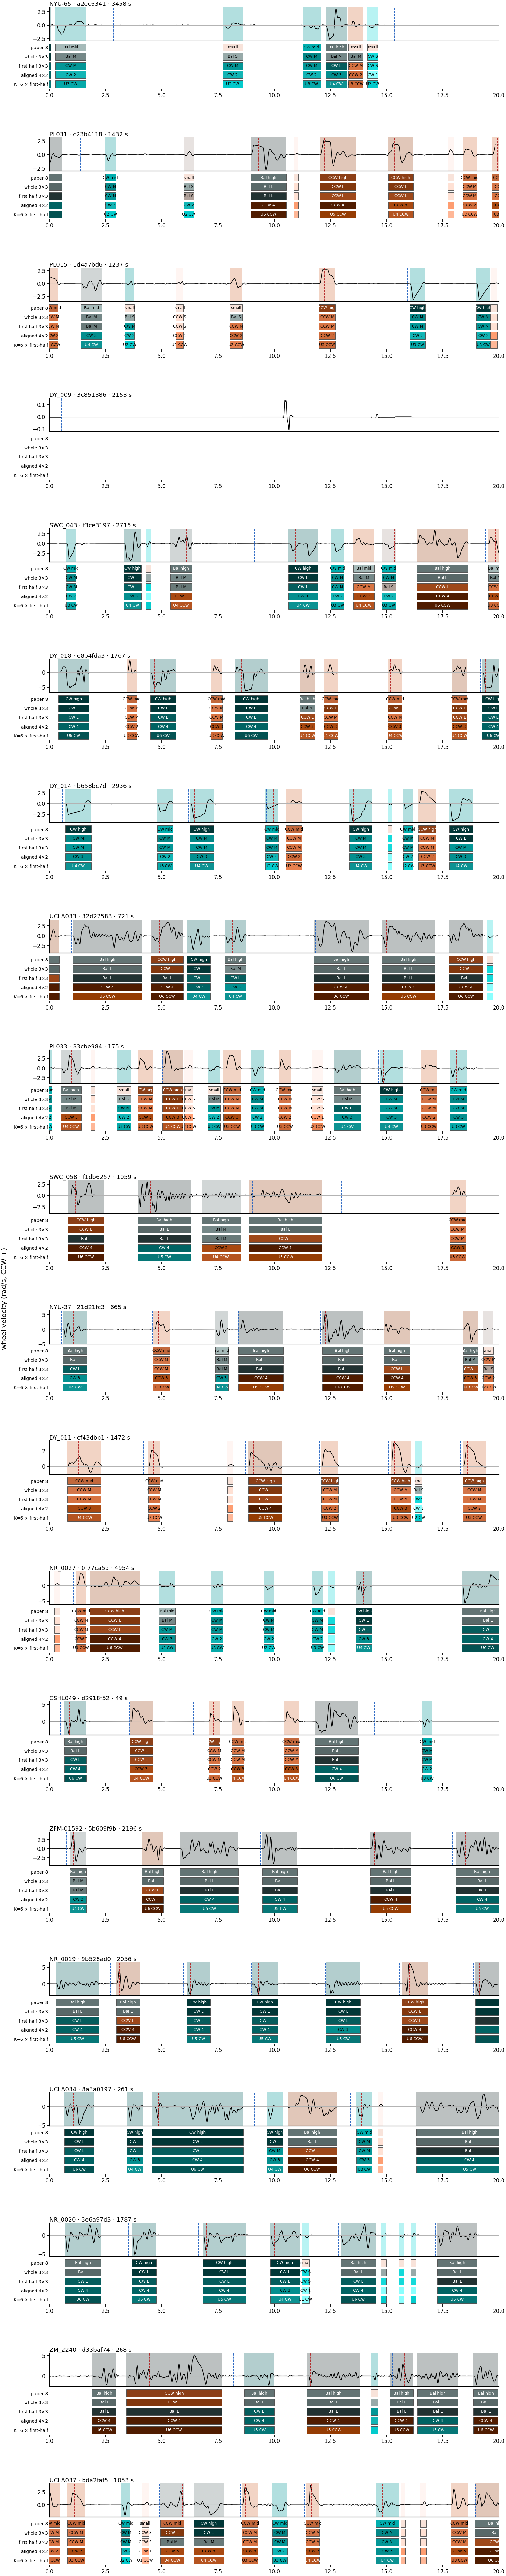

In [27]:
K3 = MODELS[3]; N3 = NAMES[3]; C3 = COLS[3]
TIER = {1: 'S', 2: 'M', 3: 'L'}
SHORT = [f"{n.split()[0]} {TIER[int(n.split()[1])]}" for n in N3]
WIN2 = 20.0
picks2 = coh.groupby('mouse').sample(1, random_state=7).sample(20, random_state=7)
rng2 = np.random.default_rng(7)
TIER = {1: 'S', 2: 'M', 3: 'L'}
HSHORT = [f"{n.split()[0]} {TIER[int(n.split()[1])]}" for n in HNAMES[3]]
KA = 4
labA = IA[f'al{KA}'].values
vigA = [np.log(np.median(IA.peak.values[labA == c])) for c in range(KA)]
colA = ps.state_palette(np.repeat(vigA, 2), gap=-wmc.CHROMA_SCALE * np.tile([-1, 1], KA), hues=wmc.WHEEL_HUES)
nameA = [f'{"CCW" if j % 2 else "CW"} {j // 2 + 1}' for j in range(2 * KA)]
# no split K = 6, split post hoc by first-half sign: state = cluster * 2 + (CCW)
U6N = [f'U{c + 1} {"CCW" if j else "CW"}' for c in range(6) for j in (0, 1)]
U6C = ps.state_palette(np.repeat(np.log(UDESC[6].peak_rad_s.values), 2), gap=-wmc.CHROMA_SCALE * np.tile([-1, 1], 6), hues=wmc.WHEEL_HUES)
SN8 = [n.replace('left', 'CW').replace('right', 'CCW').replace('both', 'Bal') for n in _names8[1:]]
# rows: (label, column, names, colours, dark-text test)
ROWS = [('paper 8', 's8', SN8, COL8, lambda c: 'high' in SN8[c]),
        ('whole 3×3', 'k3', SHORT, C3, lambda c: K3['desc'].peak_rad_s[c] > 2.5),
        ('first half 3×3', 'h3', HSHORT, HCOLS[3], lambda c: HMODELS[3]['desc'].peak_rad_s[c] > 2.5),
        (f'aligned {KA}×2', f'al{KA}x', nameA, colA, lambda c: c // 2 == KA - 1),
        ('K=6 × first-half', 'u6_h2', U6N, U6C, lambda c: UDESC[6].peak_rad_s[c // 2] > 2.5)]
nr = len(ROWS)
H = 20 * (0.85 + 0.2 * nr) + 0.6
fig = plt.figure(figsize=(7.2, H))
gs = fig.add_gridspec(20, 1, hspace=0.6, top=1 - 0.4 / H, bottom=0.02, left=0.1, right=0.99)
rng2 = np.random.default_rng(7)
for i, (m, e) in enumerate(zip(picks2.mouse, picks2.eid)):
    t, v, iv, tr = wmc.load_session('proficient', m, e)
    q = IA[IA.eid == e]
    starts = tr.intervals_0.values[(tr.intervals_0.values > q.onset.min()) & (tr.intervals_0.values < q.offset.max() - WIN2)]
    t0 = rng2.choice(starts)
    g = gs[i].subgridspec(2, 1, height_ratios=[2.0, 0.55 * nr], hspace=0.05)
    axv, axs = fig.add_subplot(g[0]), fig.add_subplot(g[1])
    sel = (t >= t0) & (t <= t0 + WIN2)
    for _, r in q[(q.offset >= t0) & (q.onset <= t0 + WIN2)].iterrows():
        x0, x1 = r.onset - wmc.PAD_S - t0, r.offset + wmc.PAD_S - t0
        axv.axvspan(x0, x1, color=HCOLS[3][int(r.h3)], alpha=0.3, lw=0)
        for j, (_, col, names, cols, dark) in enumerate(ROWS):
            c = int(r[col]); y0 = 1 - (j + 1) / nr
            axs.axvspan(x0, x1, ymin=y0 + 0.1 / nr, ymax=y0 + 0.9 / nr, color=cols[c], lw=0.3, ec='0.3')
            if x1 - x0 > 0.3:
                axs.text((x0 + x1) / 2, y0 + 0.5 / nr, names[c], ha='center', va='center', fontsize=4,
                         clip_on=True, color='w' if dark(c) else 'k')
    axv.plot(t[sel] - t0, v[sel], color='k', lw=0.6); axv.axhline(0, color='0.7', lw=0.4)
    for ev, col in (('stimOn_times', '#1f5fbf'), ('feedback_times', '#b22222')):
        for xx in tr[ev].values - t0:
            if 0 <= xx <= WIN2:
                axv.axvline(xx, color=col, lw=0.6, ls='--')
    axv.set(xlim=(0, WIN2), xticks=[]); axv.tick_params(labelsize=5.5)
    axv.set_title(f'{m} · {e[:8]} · {t0:.0f} s', fontsize=6, pad=1.5, loc='left')
    axs.set(xlim=(0, WIN2), ylim=(0, 1), yticks=1 - (np.arange(nr) + 0.5) / nr, yticklabels=[r_[0] for r_ in ROWS])
    axs.tick_params(axis='y', length=0, labelsize=4.5); axs.tick_params(axis='x', labelsize=5.5)
    for s_ in axs.spines.values(): s_.set_visible(False)
fig.text(0.005, 0.5, 'wheel velocity (rad/s, CCW +)', rotation=90, va='center', fontsize=7)
plt.show()